# Task 3 — jabłka i pomidory: analiza danych i segmentacja
Celem jest sprawdzenie, czy usunięcie tła ułatwi późniejszą klasyfikację. Zachowujemy oryginalny podział train/test. Parametry i przykłady segmentacji dobieramy wyłącznie na train. Nie ma masek wzorcowych, więc nie można podać wiarygodnego IoU/Dice.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import cv2
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'apples_tomatoes').exists() else Path.cwd() / 'third_task'
DATA = ROOT / 'apples_tomatoes'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110})
SEED = 42
def read_rgb(path):
    with Image.open(path) as im:
        return np.array(ImageOps.exif_transpose(im).convert('RGB'))


## 1. Inwentaryzacja i kontrola jakości

label,apples,tomatoes
split,,
test,54,43
train,164,130


width             height             mean_brightness            \
                 min median  max    min median  max             min    median   
split label                                                                     
test  apples     100  223.5  300    100  194.0  272        0.174471  0.687817   
      tomatoes   100  225.0  329    100  183.0  275        0.248331  0.437654   
train apples     100  225.0  318    100  194.0  283        0.206796  0.713827   
      tomatoes   100  225.0  335    100  183.0  275        0.250006  0.490871   

                          
                     max  
split label               
test  apples    0.902591  
      tomatoes  0.889199  
train apples    0.937399  
      tomatoes  0.949702

Obrazy: 391 | Błędy odczytu: 0
Rozdzielczości: {(100, 100): 98, (150, 150): 2, (159, 159): 16, (176, 177): 2, (177, 118): 4, (177, 133): 2, (177, 176): 2, (178, 283): 1, (180, 180): 1, (183, 275): 6, (183, 276): 1, (185, 272): 1, (186, 271): 1, (187, 269): 1, (187, 270): 1, (194, 259): 6, (194, 260): 1, (195, 258): 1, (196, 196): 6, (197, 255): 1, (201, 250): 1, (206, 245): 1, (208, 242): 1, (210, 240): 1, (212, 237): 1, (215, 143): 2, (215, 234): 1, (216, 233): 5, (218, 231): 2, (219, 230): 1, (220, 229): 3, (221, 228): 1, (223, 226): 2, (224, 224): 4, (224, 225): 3, (225, 224): 3, (225, 225): 88, (227, 222): 3, (228, 221): 1, (229, 220): 1, (230, 219): 1, (231, 218): 1, (234, 215): 1, (236, 214): 1, (237, 213): 1, (238, 212): 1, (240, 210): 1, (242, 208): 1, (243, 207): 1, (245, 205): 1, (248, 204): 1, (249, 202): 1, (251, 201): 2, (252, 200): 1, (255, 198): 1, (258, 195): 2, (259, 194): 16, (259, 195): 2, (260, 194): 2, (261, 193): 1, (262, 192): 2, (264, 191): 2, (266, 189): 2, (26

,split,label,path
10,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
11,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
12,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
13,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
14,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
16,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
42,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
44,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
50,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
51,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...


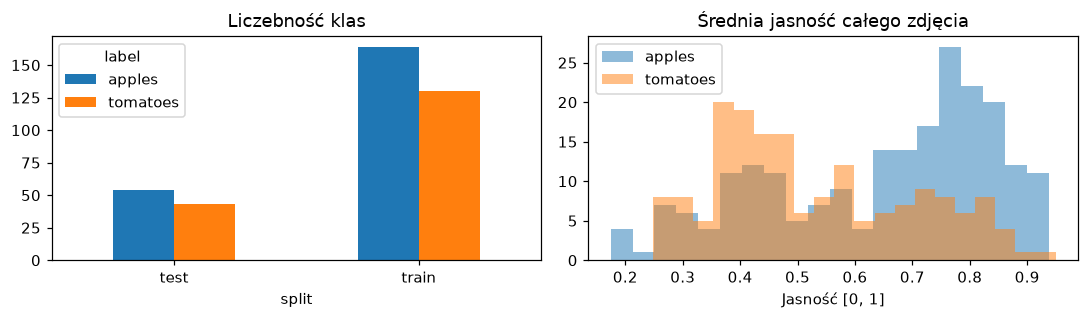

In [2]:
rows, errors = [], []
for path in sorted(DATA.rglob('*')):
    if not path.is_file(): continue
    try:
        rgb = read_rgb(path)
        rows.append(dict(path=str(path), split=path.relative_to(DATA).parts[0],
                         label=path.parent.name, width=rgb.shape[1], height=rgb.shape[0],
                         bytes=path.stat().st_size,
                         sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                         pixel_hash=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest(),
                         mean_brightness=float(rgb.mean()/255)))
    except Exception as exc:
        errors.append((str(path), str(exc)))
df = pd.DataFrame(rows)
counts = pd.crosstab(df['split'], df['label'])
display(counts)
display(df.groupby(['split','label'])[['width','height','mean_brightness']].agg(['min','median','max']))
print('Obrazy:', len(df), '| Błędy odczytu:', len(errors))
print('Rozdzielczości:', df.groupby(['width','height']).size().to_dict())
print('Nadmiarowe identyczne pliki:', df.sha256.duplicated().sum())
print('Nadmiarowe identyczne obrazy:', df.pixel_hash.duplicated().sum())
leak = df.groupby('pixel_hash').filter(lambda g: g['split'].nunique() > 1)
print('Obrazy występujące w obu splitach:', len(leak))
display(leak[['split','label','path']])
if errors: display(errors)
df.to_csv(OUT / 'dataset_inventory.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10,3))
counts.plot.bar(ax=axes[0], rot=0, title='Liczebność klas')
for label, g in df.groupby('label'):
    axes[1].hist(g.mean_brightness, bins=20, alpha=.5, label=label)
axes[1].set(title='Średnia jasność całego zdjęcia', xlabel='Jasność [0, 1]')
axes[1].legend(); plt.tight_layout(); plt.show()


## 2. Przykłady danych treningowych
Stałe losowanie po klasach pokazuje zróżnicowanie obiektów, oświetlenia i tła.

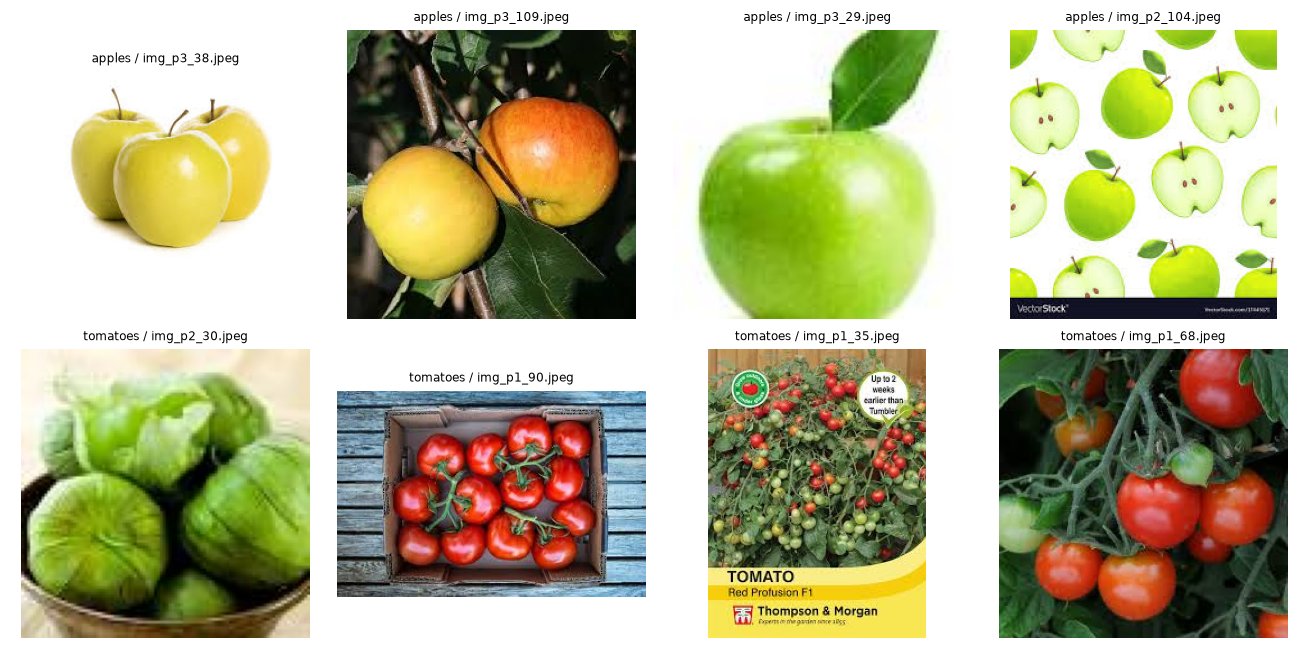

In [3]:
train = df[df.split == 'train'].copy()
examples = pd.concat([g.sample(min(4,len(g)), random_state=SEED) for _,g in train.groupby('label')])
fig, axes = plt.subplots(2,4,figsize=(12,6))
for ax, row in zip(axes.flat, examples.itertuples()):
    ax.imshow(read_rgb(row.path)); ax.set_title(f'{row.label} / {Path(row.path).name}', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.savefig(OUT/'dataset_examples.png', bbox_inches='tight'); plt.show()


## 3. Segmentacja bez etykiet masek
Porównujemy dwa proste warianty: próg nasycenia HSV (kolorowy owoc kontra mało nasycone tło) oraz odległość koloru od tła oszacowanego z brzegu obrazu w przestrzeni Lab z progiem Otsu. Oba warianty czyszczą maskę morfologicznie, zostawiają największy obszar i wypełniają jego wnętrze. To zakłada jeden główny owoc na zdjęciu. Wypełnienie może usunąć prawdziwe otwory, a największy obszar może być fragmentem tła — oglądamy także trudne przypadki.

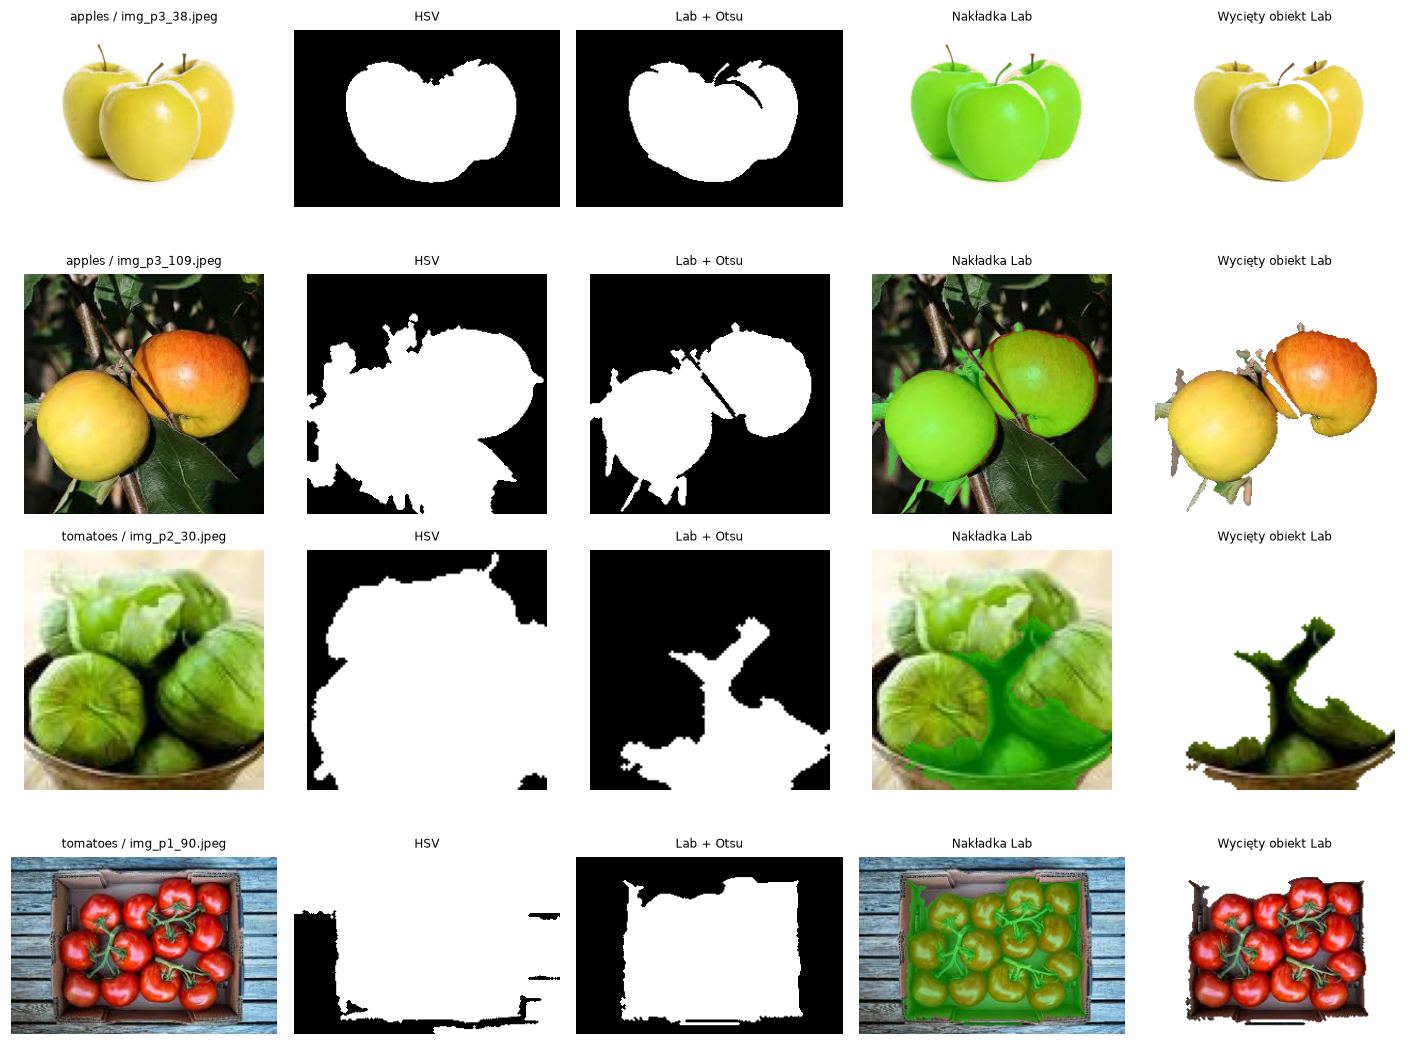

In [4]:
def clean_mask(mask):
    mask = mask.astype(np.uint8)*255
    k = max(3, int(round(min(mask.shape)*.012)) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k,k))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = np.zeros_like(mask)
    if contours: cv2.drawContours(out, [max(contours,key=cv2.contourArea)], -1, 255, -1)
    return out > 0

def segment(rgb, method='lab'):
    # Wspólna skala robocza ogranicza koszt i stabilizuje morfologię.
    h,w = rgb.shape[:2]
    scale = min(1, 384/max(h,w))
    small = cv2.resize(rgb, (max(1,round(w*scale)),max(1,round(h*scale))))
    if method == 'hsv':
        hsv = cv2.cvtColor(small, cv2.COLOR_RGB2HSV)
        raw = (hsv[:,:,1] > 55) & (hsv[:,:,2] > 35)
    else:
        lab = cv2.cvtColor(small, cv2.COLOR_RGB2LAB).astype(np.float32)
        b = max(1, round(min(lab.shape[:2])*.04))
        border = np.concatenate([lab[:b].reshape(-1,3), lab[-b:].reshape(-1,3),
                                 lab[:,:b].reshape(-1,3), lab[:,-b:].reshape(-1,3)])
        background = np.median(border, axis=0)
        distance = np.linalg.norm(lab-background, axis=2)
        distance = np.uint8(np.clip(distance,0,255))
        _, raw = cv2.threshold(distance,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
        raw = raw > 0
    cleaned = clean_mask(raw)
    return cv2.resize(cleaned.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST).astype(bool)

def show_segmentation(frame, filename):
    fig, axes = plt.subplots(len(frame),5,figsize=(13,2.5*len(frame)),squeeze=False)
    for axs, row in zip(axes,frame.itertuples()):
        rgb = read_rgb(row.path); hsv = segment(rgb,'hsv'); mask = segment(rgb,'lab')
        overlay = rgb.copy(); overlay[mask] = (.6*rgb[mask]+.4*np.array([0,255,0])).astype(np.uint8)
        cutout = np.full_like(rgb,255); cutout[mask] = rgb[mask]
        for ax, im, title in zip(axs,[rgb,hsv,mask,overlay,cutout],
                                [row.label+' / '+Path(row.path).name,'HSV','Lab + Otsu','Nakładka Lab','Wycięty obiekt Lab']):
            ax.imshow(im,cmap='gray' if im.ndim==2 else None); ax.set_title(title,fontsize=8); ax.axis('off')
    plt.tight_layout(); plt.savefig(OUT/filename,bbox_inches='tight'); plt.show()
show_segmentation(examples.groupby('label',sort=False).head(2),'segmentation_examples.png')


## 4. Diagnostyka masek na całym train
Udział maski i kontakt z brzegiem służą do wykrywania podejrzanych wyników. Nie mierzą dokładności segmentacji. Porównanie metod nie zastępuje ręcznej anotacji.

hsv_fraction                lab_fraction                      \
                  min    median  max          min    median       max   
label                                                                   
apples       0.000000  0.510242  1.0     0.018300  0.322657  0.762104   
tomatoes     0.062014  0.778553  1.0     0.008217  0.286894  0.759500   

         agreement_iou                      
                   min    median       max  
label                                       
apples             0.0  0.849228  0.997138  
tomatoes           0.0  0.379515  0.992835

Maski Lab wymagające przeglądu: 40 / 294


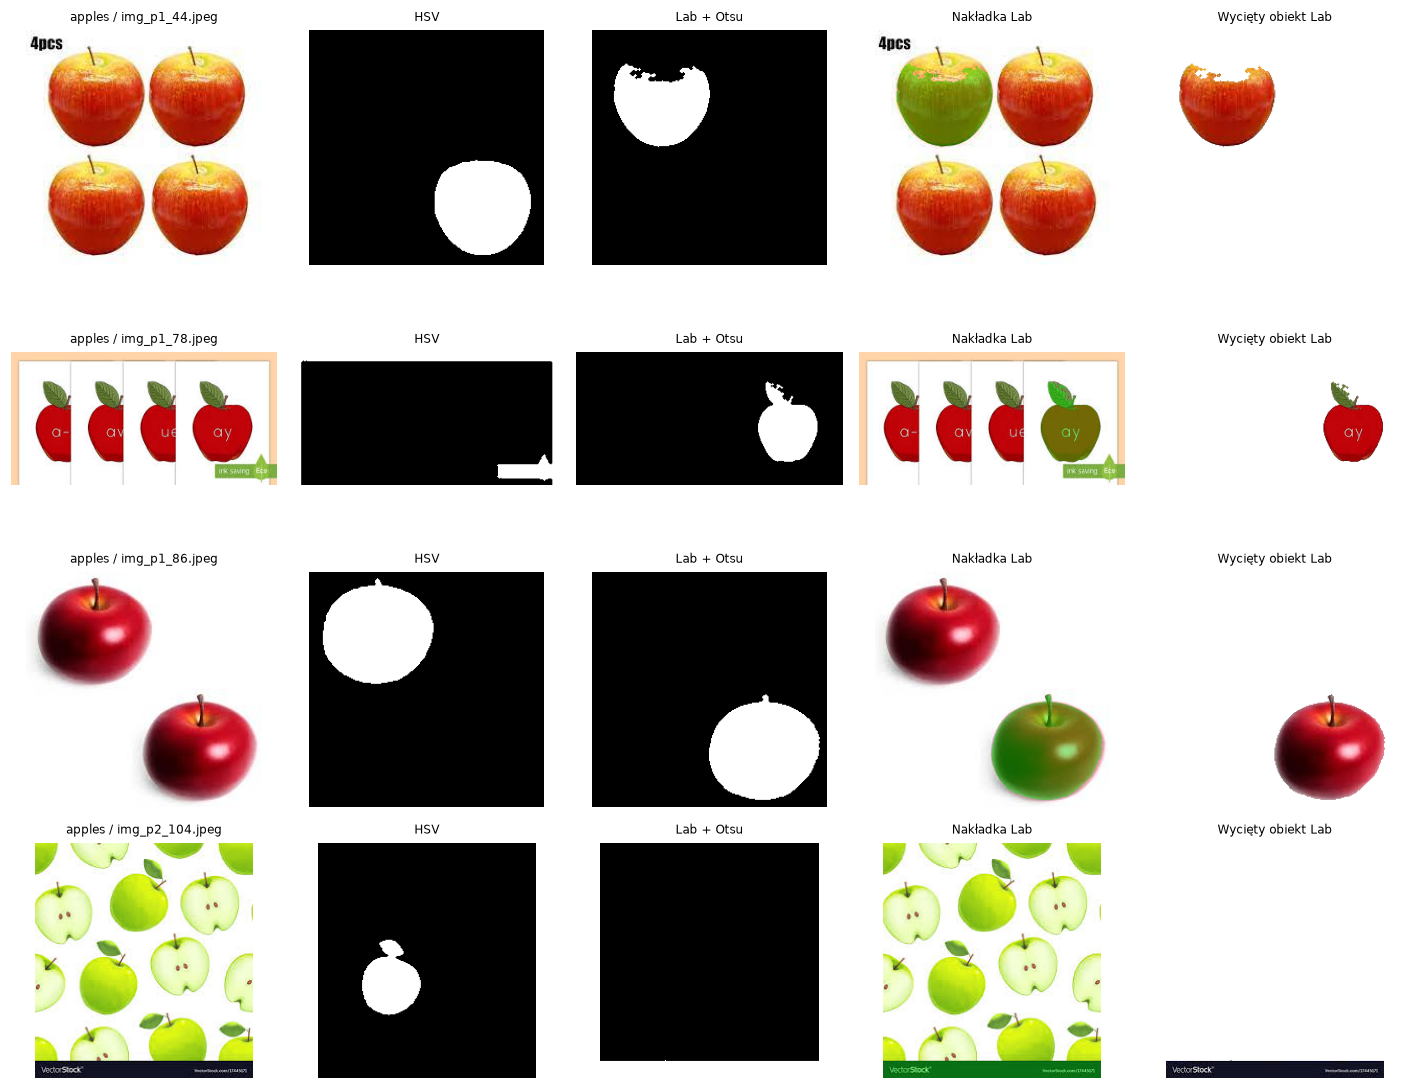

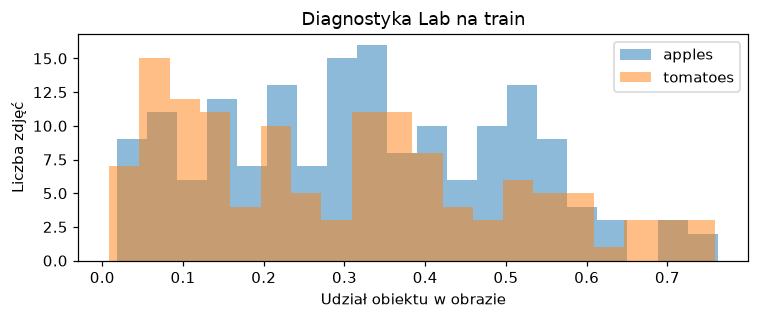

In [5]:
stats=[]
for row in train.itertuples():
    rgb=read_rgb(row.path)
    a,b=segment(rgb,'hsv'),segment(rgb,'lab')
    edge=np.concatenate([b[0],b[-1],b[:,0],b[:,-1]])
    stats.append(dict(path=row.path,label=row.label,hsv_fraction=a.mean(),lab_fraction=b.mean(),
                      border_fraction=edge.mean(),agreement_iou=(a&b).sum()/max(1,(a|b).sum())))
masks=pd.DataFrame(stats)
display(masks.groupby('label').agg({'hsv_fraction':['min','median','max'],
                                  'lab_fraction':['min','median','max'],
                                  'agreement_iou':['min','median','max']}))
masks['flag']=(masks.lab_fraction<.05)|(masks.lab_fraction>.90)|(masks.border_fraction>.25)
print('Maski Lab wymagające przeglądu:',int(masks.flag.sum()),'/',len(masks))
masks.to_csv(OUT/'segmentation_diagnostics_train.csv',index=False)
# Największa rozbieżność metod: automatyczny wybór trudnych przypadków bez testu.
hard=masks.nsmallest(4,'agreement_iou')
show_segmentation(hard,'segmentation_difficult.png')
fig,ax=plt.subplots(figsize=(7,3))
for label,g in masks.groupby('label'): ax.hist(g.lab_fraction,bins=20,alpha=.5,label=label)
ax.set(xlabel='Udział obiektu w obrazie',ylabel='Liczba zdjęć',title='Diagnostyka Lab na train'); ax.legend(); plt.tight_layout(); plt.show()


## 5. Wnioski i dalszy eksperyment
- Segmentacja daje maskę do pomiaru pola, obwodu, kolistości, proporcji oraz koloru samego owocu. Kolor tła nie powinien wtedy dominować cech.
- HSV może pomijać jasne fragmenty owocu i przejmować kolorowe tło. Lab zakłada reprezentatywny kolor brzegu; obiekt dotykający brzegu lub niejednolite tło może ten warunek naruszać.
- Siatki wyżej pokazują wyniki i największe rozbieżności, nie dowód poprawności. Do wyboru metody warto ręcznie oznaczyć maski dla reprezentatywnego podzbioru train i porównać IoU/Dice.
- Nazwy `img_p…` mogą kodować serie ujęć. Bez dokumentacji nie wiemy, czy train i test zawierają różne zdjęcia tego samego owocu. Kontrola identycznych pikseli nie wykrywa takiego przecieku.
- Kolejny krok: porównać klasyfikator na cechach całego zdjęcia i na cechach maski, walidując wyłącznie na train (grupując po obiekcie/serii, jeśli uda się je ustalić). Test zachować do końcowej oceny. Nie wybieramy segmentacji na podstawie wyniku testowego.

## Wyniki wykonanej analizy
- **391 obrazów: 294 train i 97 test**, brak błędów odczytu. Rozmiary są zróżnicowane.
- **23 nadmiarowe kopie identycznych obrazów** w całym zbiorze. **26 plików** należy do grup identycznych pikselowo obrazów występujących w obu splitach. Przed oceną klasyfikatora trzeba rozwiązać ten przeciek; oryginalnych plików nie zmieniono.
- Dane obejmują fotografie pojedynczych i wielu owoców, ilustracje, wzory i obrazy z tekstem. Założenie jednego głównego owocu nie jest spełnione w całym zbiorze.
- Na przykładach Lab oddziela jabłka od białego tła i część jabłek od liści. Zielone pomidory są wycinane niepoprawnie; skrzynka zostaje razem z pomidorami. Przy wielu rozłącznych owocach największy komponent zachowuje tylko jeden.
- Heurystyka oznaczyła **40/294** masek Lab do przeglądu. To liczba ostrzeżeń, nie liczba wszystkich błędów.
- Wniosek: segmentacja jest sensownym eksperymentem wstępnym, ale ten prosty wariant nie nadaje się jeszcze do automatycznego przetwarzania całego datasetu. Najpierw należy określić, czy chcemy maskę wszystkich owoców czy pojedynczego obiektu, i zweryfikować ją na ręcznie oznaczonych przykładach train.


# 6. Tekstury i klasyfikacja
Korzystamy z zapisanych masek `segmented_dataset/masks`, bez ponownej segmentacji. Cechy opisują wyłącznie jasność i jej lokalne zmiany — bez koloru, wielkości maski i tła. Porównamy LBP, GLCM i połączenie obu. Brak masek wzorcowych oznacza, że błędna segmentacja może dostarczać tekstury tła zamiast owocu.

**Maskowanie jest istotne:** nie liczymy tekstury na prostokątnym wycinku z czarnym tłem. Dla LBP całe sąsiedztwo musi leżeć wewnątrz maski, a dla GLCM oba piksele pary muszą należeć do maski. Zachowujemy oryginalną rozdzielczość; różna skala owoców pozostaje ograniczeniem.

In [6]:
from skimage.feature import local_binary_pattern, graycoprops
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (balanced_accuracy_score, accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
import json

SEG = ROOT / 'segmented_dataset'
manifest = pd.read_csv(SEG / 'manifest.csv')

def texture_features(rgb, mask):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    feats = {}
    # Uniform LBP: histogram 10 kategorii dla 8 sąsiadów.
    interior = cv2.erode(mask.astype(np.uint8), np.ones((3,3), np.uint8),
                         borderType=cv2.BORDER_CONSTANT, borderValue=0).astype(bool)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    hist = np.bincount(lbp[interior].astype(int), minlength=10).astype(float)
    hist = hist / hist.sum() if hist.sum() else np.full(10, np.nan)
    feats.update({f'lbp_{i}':v for i,v in enumerate(hist)})
    # Symetryczna GLCM, 16 poziomów, odległości 1/2 i cztery kierunki.
    q = (gray.astype(np.uint16)*16//256).astype(np.uint8)
    props = ['contrast','dissimilarity','homogeneity','ASM','energy','correlation']
    for d in (1,2):
        values = {prop:[] for prop in props}
        for dy,dx in ((0,d),(d,0),(d,d),(d,-d)):
            h,w=mask.shape
            ya=slice(max(0,-dy),h-max(0,dy)); yb=slice(max(0,dy),h-max(0,-dy))
            xa=slice(max(0,-dx),w-max(0,dx)); xb=slice(max(0,dx),w-max(0,-dx))
            valid = mask[ya,xa] & mask[yb,xb]
            if not valid.any(): continue
            a,b=q[ya,xa][valid],q[yb,xb][valid]
            mat=np.bincount(a.astype(int)*16+b,minlength=256).reshape(16,16).astype(float)
            mat=mat+mat.T; mat/=mat.sum()
            for prop in props:
                values[prop].append(float(graycoprops(mat[:,:,None,None],prop)[0,0]))
        for prop,v in values.items():
            feats[f'glcm_d{d}_{prop}_mean']=np.mean(v) if v else np.nan
            feats[f'glcm_d{d}_{prop}_std']=np.std(v) if v else np.nan
    return feats, int(interior.sum())

records=[]
for row in manifest.itertuples():
    source=DATA / row.source
    rgb=read_rgb(source)
    with Image.open(SEG / row.mask) as im: mask=np.array(im)>0
    features, n_interior=texture_features(rgb,mask)
    records.append(dict(source=row.source,split=row.split,label=row.label,
                        pixel_hash=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest(),
                        interior_pixels=n_interior,**features))
textures=pd.DataFrame(records)
feature_cols=[c for c in textures if c.startswith(('lbp_','glcm_'))]
textures.to_csv(OUT/'texture_features.csv',index=False)
print('Liczba cech tekstury:',len(feature_cols))
print('Maski bez pełnego sąsiedztwa LBP:',int((textures.interior_pixels==0).sum()))
display(textures.groupby(['split','label']).size().rename('images').to_frame())


Liczba cech tekstury: 34
Maski bez pełnego sąsiedztwa LBP: 0


images
split label           
test  apples        54
      tomatoes      43
train apples       164
      tomatoes     130

## 6.1. Wizualizacja tekstury
Białe tło poniżej służy tylko prezentacji. Histogram LBP i mapa lokalnych wzorców obejmują wyłącznie piksele z pełnym sąsiedztwem wewnątrz maski. Przykłady wybieramy z train.

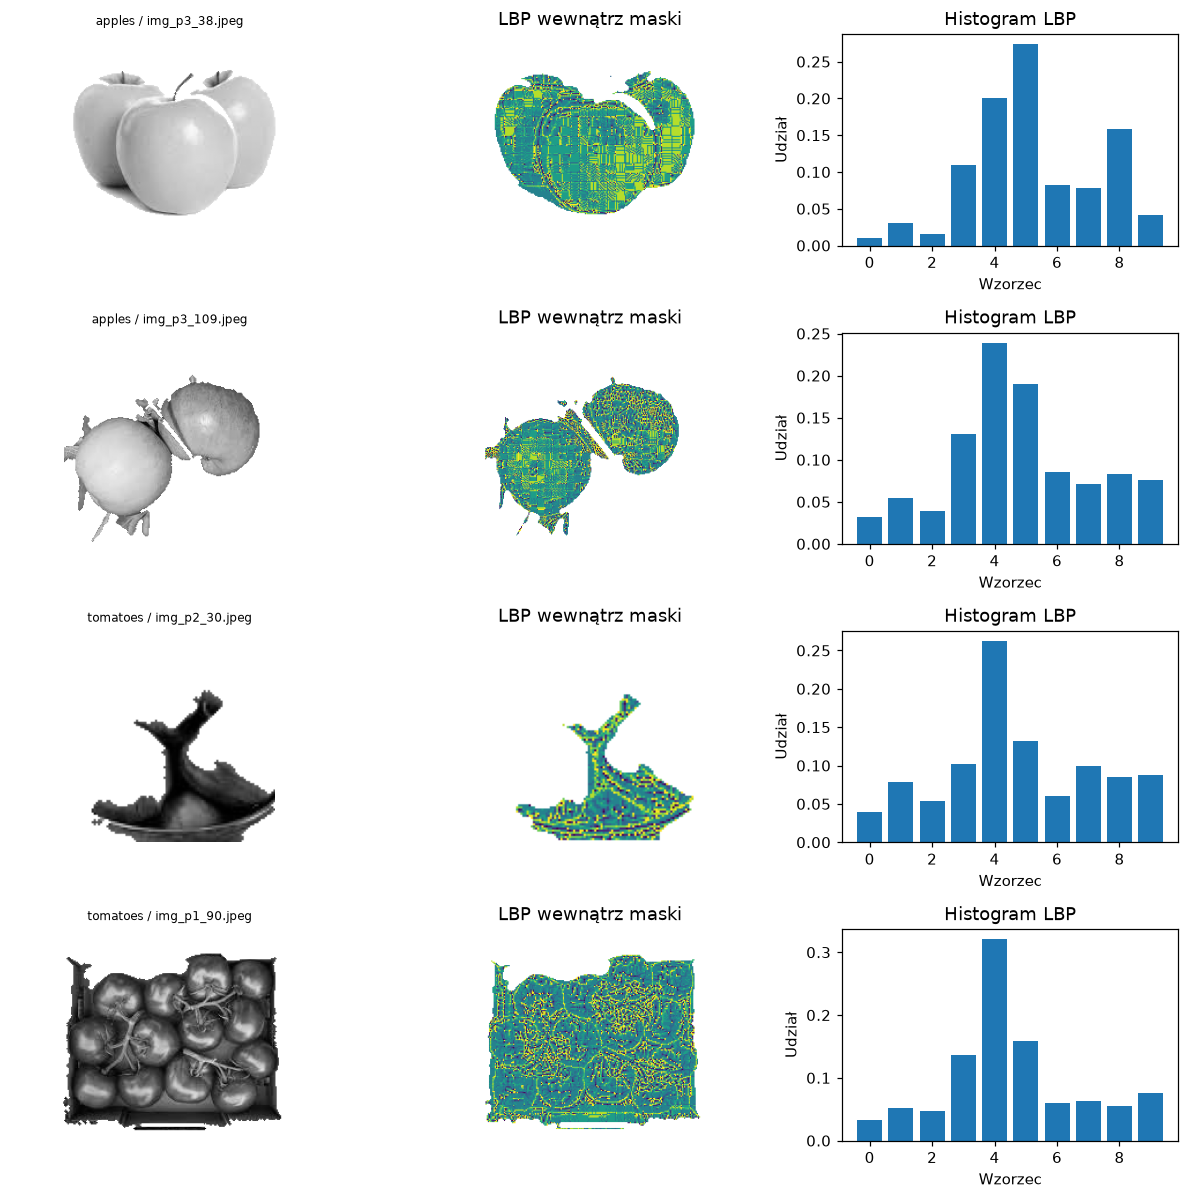

In [7]:
fig,axes=plt.subplots(4,3,figsize=(11,11))
selected=pd.concat([g.sample(2,random_state=SEED) for _,g in textures[textures.split=='train'].groupby('label')])
for axs,row in zip(axes,selected.itertuples()):
    rgb=read_rgb(DATA/row.source)
    with Image.open(SEG/'masks'/(row.source+'.png')) as im: mask=np.array(im)>0
    gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
    interior=cv2.erode(mask.astype(np.uint8),np.ones((3,3),np.uint8),borderType=cv2.BORDER_CONSTANT,borderValue=0)>0
    lbp=local_binary_pattern(gray,8,1,'uniform')
    axs[0].imshow(np.ma.array(gray,mask=~mask),cmap='gray',vmin=0,vmax=255)
    axs[0].set_title(row.label+' / '+Path(row.source).name,fontsize=8)
    axs[1].imshow(np.ma.array(lbp,mask=~interior),cmap='viridis',vmin=0,vmax=9)
    axs[1].set_title('LBP wewnątrz maski')
    for ax in axs[:2]: ax.axis('off')
    axs[2].bar(range(10),[getattr(row,f'lbp_{i}') for i in range(10)])
    axs[2].set(title='Histogram LBP',xlabel='Wzorzec',ylabel='Udział')
plt.tight_layout(); plt.savefig(OUT/'texture_examples.png',bbox_inches='tight'); plt.show()


## 6.2. Podział i dobór klasyfikatora
Usuwamy nadmiarowe identyczne obrazy osobno w train i test, a z testu także wszystkie obrazy identyczne z train. Nie usuwamy zdjęć na podstawie jakości maski: mierzymy cały potok, łącznie z jego błędami. Brakujące cechy imputujemy medianą wyliczoną wyłącznie na foldzie treningowym.

Parametry SVM i rodzaj cech wybieramy przez 5-fold walidację wyłącznie na train. Grupowanie po hashu pikseli zabezpiecza przed identycznymi obrazami w foldach; nie gwarantuje rozdzielenia różnych zdjęć tego samego owocu. Test wykorzystujemy raz dla wybranego wariantu. Punktem odniesienia jest przewidywanie najczęstszej klasy.

Kontrola spójności etykiet obejmuje cały zbiór: wszystkie grupy identycznych obrazów ze sprzecznymi etykietami wyłączamy przed eksperymentem, bez zgadywania poprawnej klasy. Jest to jawna korekta jakości danych, wykorzystująca etykiety train i test, a nie dobór parametrów modelu.

Sprzecznie opisane obrazy: 2 w grupach: 1


,source,label
50,test/apples/img_p3_79.jpeg,apples
277,train/tomatoes/img_p1_28.jpeg,tomatoes


Po usunięciu duplikatów: train = 283 test = 84


label,apples,tomatoes
split,,
test,44,40
train,156,127


,features,cv_balanced_accuracy,cv_std,params
2,LBP + GLCM,0.711971,0.032856,"{'svm__C': 100, 'svm__gamma': 'scale'}"
1,GLCM,0.700265,0.054404,"{'svm__C': 100, 'svm__gamma': 'scale'}"
0,LBP,0.688857,0.077007,"{'svm__C': 10, 'svm__gamma': 'scale'}"


,model,accuracy,balanced_accuracy,f1_macro
0,Dummy: najczęstsza klasa,0.52381,0.500000,0.343750
1,SVM / LBP + GLCM,0.77381,0.771591,0.772228


              precision    recall  f1-score   support

      apples       0.77      0.82      0.79        44
    tomatoes       0.78      0.72      0.75        40

    accuracy                           0.77        84
   macro avg       0.77      0.77      0.77        84
weighted avg       0.77      0.77      0.77        84



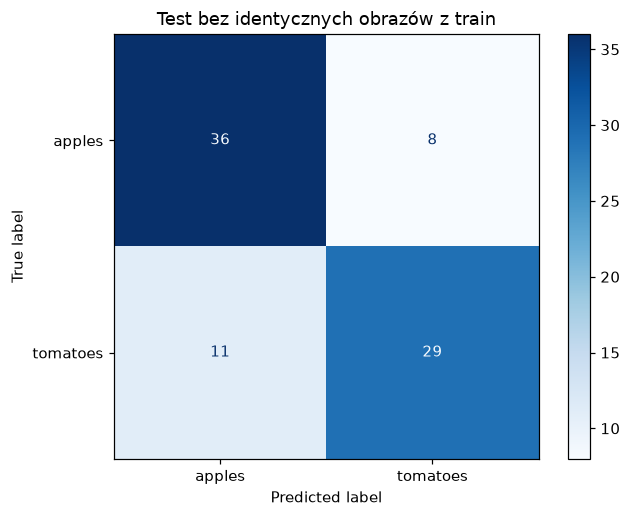

Wybrany wariant: LBP + GLCM | Parametry: {'svm__C': 100, 'svm__gamma': 'scale'}


In [8]:
conflicts=textures.groupby('pixel_hash').label.nunique()
conflict_hashes=set(conflicts[conflicts>1].index)
conflict_rows=textures[textures.pixel_hash.isin(conflict_hashes)]
print('Sprzecznie opisane obrazy:',len(conflict_rows),'w grupach:',len(conflict_hashes))
display(conflict_rows[['source','label']])
conflict_rows.to_csv(OUT/'texture_label_conflicts.csv',index=False)
clean=textures[~textures.pixel_hash.isin(conflict_hashes)]
tr=clean[clean.split=='train'].drop_duplicates('pixel_hash').copy()
te=clean[clean.split=='test'].drop_duplicates('pixel_hash').copy()
te=te[~te.pixel_hash.isin(tr.pixel_hash)].copy()
assert not set(tr.pixel_hash)&set(te.pixel_hash)

print('Po usunięciu duplikatów: train =',len(tr),'test =',len(te))
display(pd.crosstab(pd.concat([tr,te])['split'],pd.concat([tr,te])['label']))
sets={'LBP':[c for c in feature_cols if c.startswith('lbp_')],
      'GLCM':[c for c in feature_cols if c.startswith('glcm_')],
      'LBP + GLCM':feature_cols}
cv=list(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED).split(tr,tr.label,tr.pixel_hash))
searches={}; scores=[]
for name,cols in sets.items():
    pipe=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                   ('scale',StandardScaler()),('svm',SVC(class_weight='balanced'))])
    search=GridSearchCV(pipe,{'svm__C':[.1,1,10,100], 'svm__gamma':['scale',.01,.1]},
                        scoring='balanced_accuracy',cv=cv,n_jobs=1)
    search.fit(tr[cols],tr.label)
    searches[name]=search
    scores.append(dict(features=name,cv_balanced_accuracy=search.best_score_,
                       cv_std=search.cv_results_['std_test_score'][search.best_index_],params=str(search.best_params_)))
comparison=pd.DataFrame(scores).sort_values('cv_balanced_accuracy',ascending=False)
display(comparison)
best_name=comparison.iloc[0]['features']; best=searches[best_name]; cols=sets[best_name]
pred=best.predict(te[cols])
dummy=DummyClassifier(strategy='most_frequent').fit(tr[cols],tr.label)
baseline=dummy.predict(te[cols])
results=pd.DataFrame([dict(model='Dummy: najczęstsza klasa',accuracy=accuracy_score(te.label,baseline),
                           balanced_accuracy=balanced_accuracy_score(te.label,baseline),f1_macro=f1_score(te.label,baseline,average='macro')),
                      dict(model='SVM / '+best_name,accuracy=accuracy_score(te.label,pred),
                           balanced_accuracy=balanced_accuracy_score(te.label,pred),f1_macro=f1_score(te.label,pred,average='macro'))])
display(results)
print(classification_report(te.label,pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(te.label,pred,cmap='Blues'); plt.title('Test bez identycznych obrazów z train'); plt.tight_layout()
plt.savefig(OUT/'texture_confusion_matrix.png',bbox_inches='tight'); plt.show()
comparison.to_csv(OUT/'texture_cv_results.csv',index=False)
results.to_csv(OUT/'texture_test_metrics.csv',index=False)
predictions=te[['source','label','interior_pixels']].copy(); predictions['prediction']=pred
predictions.to_csv(OUT/'texture_test_predictions.csv',index=False)
print('Wybrany wariant:',best_name,'| Parametry:',best.best_params_)


## 6.3. Interpretacja
Wynik testowy ocenia połączenie obecnej segmentacji i tekstury, a nie jakość samych masek. LBP opisuje lokalne wzorce jasności, GLCM kontrast i uporządkowanie sąsiadujących pikseli. Żadna z tych cech nie identyfikuje pomidora na podstawie koloru czy pełnego kształtu.

Błędna maska nadal może dać cechy tła; puste maski otrzymują imputowane cechy i nie dostarczają informacji o owocu. Mały test i możliwe podobne ujęcia ograniczają wiarygodność wyniku. Poprawa masek oraz porównanie z modelem na oryginalnych zdjęciach pozostają osobnymi eksperymentami; nie dostrajamy ich do tego testu.

### Wynik wykonanego eksperymentu
Po kontroli danych: **283 obrazów treningowych i 84 testowe**. Wyłączono jedną grupę dwóch identycznych obrazów ze sprzecznymi etykietami.

Najlepszy wariant walidacyjny: **LBP + GLCM, SVM RBF**, C=100, gamma=scale. Średnia balanced accuracy z 5 foldów: **71,2%**, odchylenie między foldami: **3,3 punktu procentowego** (nie jest to przedział ufności).

Na teście: **accuracy 77,4% (65/84)**, **balanced accuracy 77,2%**, **macro F1 77,2%**. Model najczęstszej klasy: accuracy 52,4%, balanced accuracy 50,0%.

Tekstury dostarczają użytecznego sygnału mimo niedoskonałych masek. Wynik nie dowodzi jednak, że model rozpoznaje wyłącznie powierzchnię owocu: błędne maski mogą zawierać tło, gałęzie i opakowania. Różna skala obrazów i podobne ujęcia również mogą wpływać na ocenę.


# 7. Segmentacja hybrydowa: kolor i kształt
Dodajemy geometryczne priory dla owoców: zaokrąglenie, wypukłość, proporcje i zgodność z dopasowaną elipsą. Kandydaci pochodzą z koloru Lab, nasycenia HSV oraz domkniętych krawędzi. Każdy kandydat musi mieć także poparcie koloru. Zachowujemy wiele rozłącznych obszarów zamiast tylko największego.

To heurystyka, nie wyuczony detektor owoców. Okrągłe elementy tła mogą przejść filtr; kiście, przekrojone owoce i przesłonięte obiekty mogą go nie spełnić. Jeżeli nie ma kandydata, wracamy do pierwotnej maski Lab, zapisując tę informację. Nie zmieniamy poprzednich wyników.

Parametry ustalamy jawnie, bez optymalizacji pod test. Ponieważ wcześniejszy wynik testowy jest już znany, poniższe porównanie jest **eksploracyjne**; ostateczne potwierdzenie wymaga nowych danych. Bez masek wzorcowych nie ogłaszamy poprawy IoU/Dice.

In [9]:
def hybrid_segment(rgb):
    h,w=rgb.shape[:2]; scale=min(1,384/max(h,w))
    img=cv2.resize(rgb,(max(1,round(w*scale)),max(1,round(h*scale))))
    hh,ww=img.shape[:2]; area_image=hh*ww
    lab=cv2.cvtColor(img,cv2.COLOR_RGB2LAB).astype(np.float32)
    b=max(1,round(min(hh,ww)*.04))
    border=np.concatenate([lab[:b].reshape(-1,3),lab[-b:].reshape(-1,3),lab[:,:b].reshape(-1,3),lab[:,-b:].reshape(-1,3)])
    distance=np.uint8(np.clip(np.linalg.norm(lab-np.median(border,axis=0),axis=2),0,255))
    _,lab_raw=cv2.threshold(distance,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    hsv=cv2.cvtColor(img,cv2.COLOR_RGB2HSV)
    hsv_raw=np.uint8((hsv[:,:,1]>55)&(hsv[:,:,2]>35))*255
    color_support=(lab_raw>0)|(hsv_raw>0)
    gray=cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)
    edges=cv2.Canny(cv2.GaussianBlur(gray,(5,5),0),50,140)
    kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))
    candidates=[]
    for source,raw in [('lab',lab_raw),('hsv',hsv_raw),('edges',edges)]:
        raw=cv2.morphologyEx(raw,cv2.MORPH_CLOSE,kernel,iterations=2)
        contours,_=cv2.findContours(raw,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)
        for contour in contours:
            area=cv2.contourArea(contour); perimeter=cv2.arcLength(contour,True)
            if area < max(25,.008*area_image) or area>.85*area_image or perimeter==0: continue
            x,y,cw,ch=cv2.boundingRect(contour)
            ratio=min(cw,ch)/max(cw,ch)
            circularity=min(1,4*np.pi*area/perimeter**2)
            hull_area=cv2.contourArea(cv2.convexHull(contour))
            solidity=area/max(hull_area,1)
            if ratio<.35 or circularity<.25 or solidity<.65: continue
            mask=np.zeros((hh,ww),np.uint8); cv2.drawContours(mask,[contour],-1,1,-1)
            mask=mask.astype(bool)
            support=float(color_support[mask].mean())
            if support<.45: continue
            ellipse_iou=0.
            if len(contour)>=5:
                ellipse=cv2.fitEllipse(contour)
                ellipse_mask=np.zeros((hh,ww),np.uint8)
                cv2.ellipse(ellipse_mask,ellipse,1,-1)
                e=ellipse_mask>0
                ellipse_iou=float((mask&e).sum()/max(1,(mask|e).sum()))
            touch=float(np.concatenate([mask[0],mask[-1],mask[:,0],mask[:,-1]]).mean())
            score=.30*circularity+.25*solidity+.15*ratio+.20*ellipse_iou+.10*support-.30*touch
            if score>=.57:
                candidates.append((score,area,mask,source))
    # Duplikaty kandydatów i kontury zagnieżdżone nie dodają nowych obiektów.
    candidates.sort(key=lambda x:(x[0],x[1]),reverse=True)
    selected=[]; combined=np.zeros((hh,ww),bool)
    for score,area,mask,source in candidates:
        if (mask&combined).sum()/max(1,mask.sum())>.25: continue
        selected.append((score,source)); combined |= mask
    fallback=not bool(selected)
    result=segment(rgb,'lab') if fallback else cv2.resize(combined.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST)>0
    return result,dict(fallback=fallback,objects=len(selected),best_shape_score=selected[0][0] if selected else np.nan)

# Kontrola przypadków brzegowych: poprawny typ i rozmiar dla stałych obrazów.
for value in (0,255):
    sample=np.full((48,64,3),value,np.uint8)
    mask,info=hybrid_segment(sample)
    assert mask.shape==(48,64) and mask.dtype==bool


## 7.1. Eksport hybrydowy i cechy tekstur
Zapisujemy wszystkie maski, obrazy RGBA, diagnostykę i cechy. Klasyfikator nadal otrzymuje tylko LBP/GLCM; kształt służy wyłącznie segmentacji.

In [10]:
HYBROOT=ROOT/'segmented_dataset_hybrid'
HYBOUT=OUT/'hybrid'; HYBOUT.mkdir(parents=True,exist_ok=True)
hybrid_records=[]; hybrid_diagnostics=[]
for row in manifest.itertuples():
    rgb=read_rgb(DATA/row.source)
    mask,info=hybrid_segment(rgb)
    relative=Path(row.source+'.png')
    for folder in ('masks','images'):
        (HYBROOT/folder/relative).parent.mkdir(parents=True,exist_ok=True)
    Image.fromarray(mask.astype(np.uint8)*255).save(HYBROOT/'masks'/relative)
    Image.fromarray(np.dstack([rgb,mask.astype(np.uint8)*255])).save(HYBROOT/'images'/relative)
    with Image.open(HYBROOT/'masks'/relative) as saved: assert np.array_equal(np.array(saved)>0,mask)
    features,n_interior=texture_features(rgb,mask)
    hybrid_records.append(dict(source=row.source,split=row.split,label=row.label,
        pixel_hash=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest(),
        interior_pixels=n_interior,**features))
    with Image.open(SEG/row.mask) as im: original=np.array(im)>0
    hybrid_diagnostics.append(dict(source=row.source,split=row.split,label=row.label,
        mask=str(Path('masks')/relative),image=str(Path('images')/relative),
        foreground_fraction=float(mask.mean()),
        old_new_iou=float((mask&original).sum()/max(1,(mask|original).sum())),**info))
hybrid_textures=pd.DataFrame(hybrid_records)
hybrid_diag=pd.DataFrame(hybrid_diagnostics)
hybrid_textures.to_csv(HYBOUT/'texture_features.csv',index=False)
hybrid_diag.to_csv(HYBROOT/'manifest.csv',index=False)
display(hybrid_diag.groupby(['split','label']).agg(images=('source','size'),
    fallback=('fallback','sum'),median_objects=('objects','median'),median_old_new_iou=('old_new_iou','median')))
print('IoU powyżej porównuje dwie predykcje, a nie poprawność segmentacji.')


images  fallback  median_objects  median_old_new_iou
split label                                                         
test  apples        54         0             2.0            0.890350
      tomatoes      43         0             4.0            0.169781
train apples       164         4             1.5            0.860568
      tomatoes     130         0             4.0            0.295007

IoU powyżej porównuje dwie predykcje, a nie poprawność segmentacji.


## 7.2. Porównanie wizualne na train
Pokazujemy te same przykłady co wcześniej oraz największe zmiany maski w train. Dobór przykładów nie używa etykiet testowych.

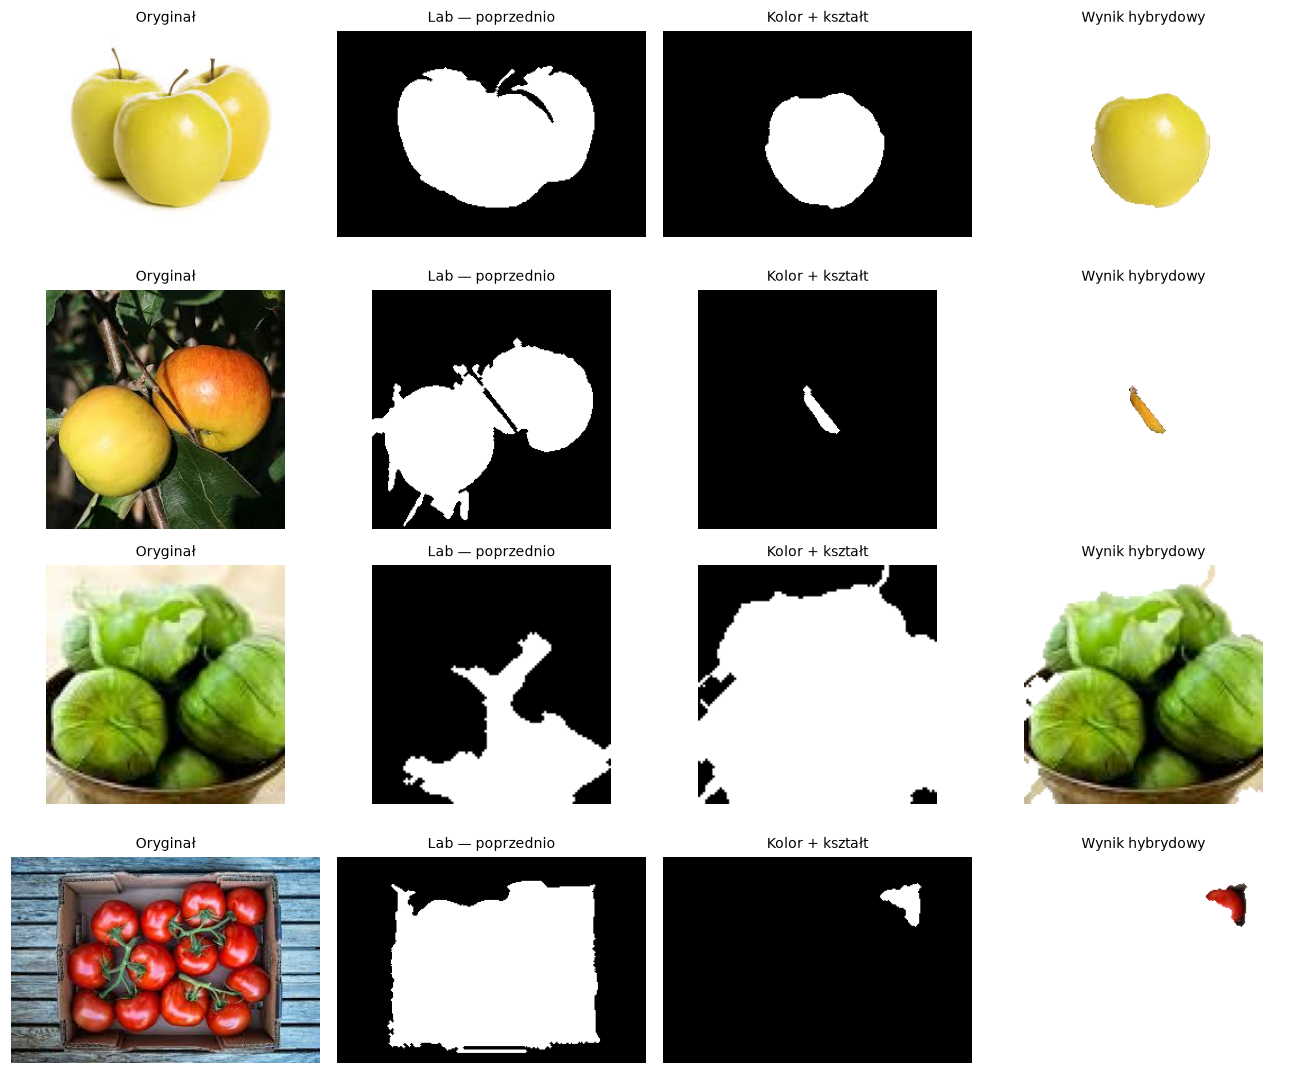

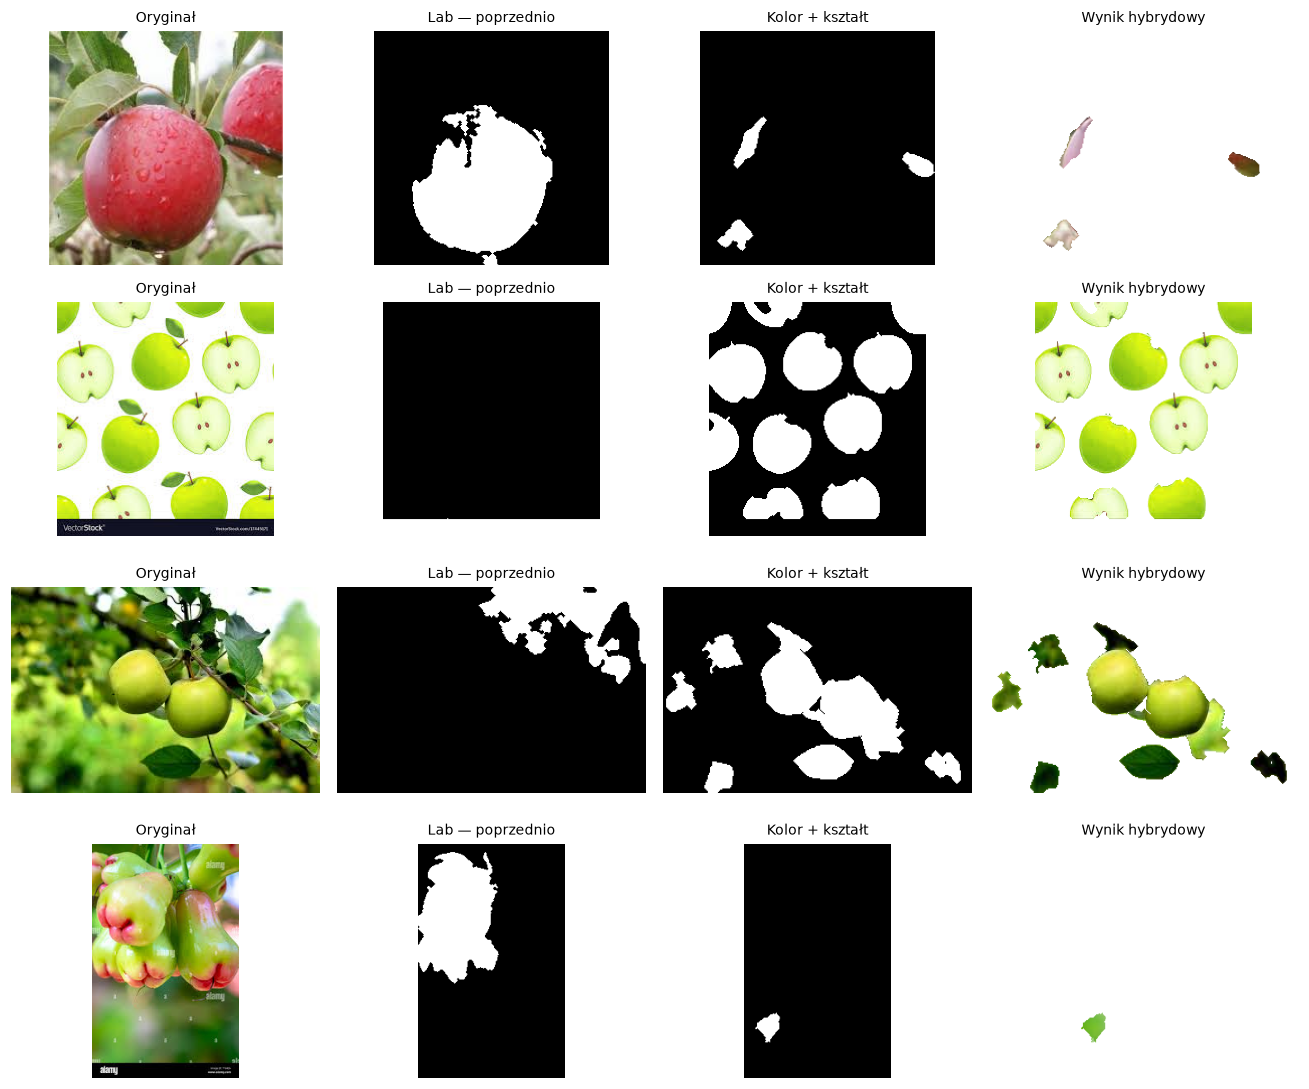

In [11]:
def show_hybrid_comparison(sources,filename):
    fig,axes=plt.subplots(len(sources),4,figsize=(12,2.5*len(sources)),squeeze=False)
    for axs,source in zip(axes,sources):
        rgb=read_rgb(DATA/source)
        with Image.open(SEG/'masks'/(source+'.png')) as im: old=np.array(im)>0
        with Image.open(HYBROOT/'masks'/(source+'.png')) as im: new=np.array(im)>0
        cut=np.full_like(rgb,255); cut[new]=rgb[new]
        for ax,im,title in zip(axs,[rgb,old,new,cut],['Oryginał','Lab — poprzednio','Kolor + kształt','Wynik hybrydowy']):
            ax.imshow(im,cmap='gray' if im.ndim==2 else None); ax.axis('off'); ax.set_title(title,fontsize=9)
        axs[0].set_ylabel(Path(source).name)
    plt.tight_layout();plt.savefig(HYBOUT/filename,bbox_inches='tight');plt.show()
fixed=[str(Path(p).relative_to(DATA)) for p in examples.groupby('label',sort=False).head(2).path]
show_hybrid_comparison(fixed,'segmentation_comparison.png')
changed=hybrid_diag[hybrid_diag.split=='train'].nsmallest(4,'old_new_iou')
show_hybrid_comparison(changed.source.tolist(),'largest_changes_train.png')


## 7.3. Klasyfikacja tekstur po segmentacji hybrydowej
Powtarzamy ten sam podział po deduplikacji, te same cechy, siatkę parametrów i foldy. Rodzaj cech i parametry SVM wybieramy wyłącznie w walidacji train. Porównanie na już oglądanym teście służy eksploracji.

Sprzecznie opisane obrazy: 2 w grupach: 1


,source,label
50,test/apples/img_p3_79.jpeg,apples
277,train/tomatoes/img_p1_28.jpeg,tomatoes


Po usunięciu duplikatów: train = 283 test = 84


label,apples,tomatoes
split,,
test,44,40
train,156,127


,features,cv_balanced_accuracy,cv_std,params
2,LBP + GLCM,0.724579,0.030739,"{'svm__C': 1, 'svm__gamma': 0.1}"
0,LBP,0.717483,0.041579,"{'svm__C': 1, 'svm__gamma': 'scale'}"
1,GLCM,0.694872,0.038727,"{'svm__C': 10, 'svm__gamma': 0.01}"


,model,accuracy,balanced_accuracy,f1_macro
0,Dummy: najczęstsza klasa,0.523810,0.500000,0.343750
1,SVM / LBP + GLCM,0.690476,0.694318,0.689773


              precision    recall  f1-score   support

      apples       0.75      0.61      0.68        44
    tomatoes       0.65      0.78      0.70        40

    accuracy                           0.69        84
   macro avg       0.70      0.69      0.69        84
weighted avg       0.70      0.69      0.69        84



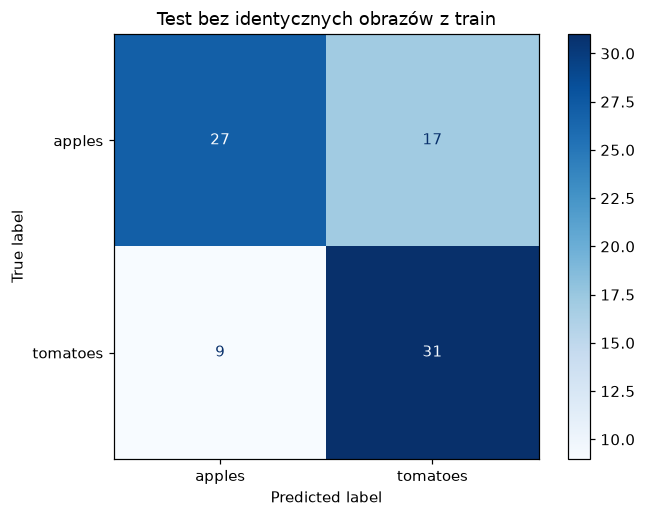

Wybrany wariant: LBP + GLCM | Parametry: {'svm__C': 1, 'svm__gamma': 0.1}


In [12]:
def evaluate_hybrid():
    conflicts=hybrid_textures.groupby('pixel_hash').label.nunique()
    conflict_hashes=set(conflicts[conflicts>1].index)
    conflict_rows=hybrid_textures[hybrid_textures.pixel_hash.isin(conflict_hashes)]
    print('Sprzecznie opisane obrazy:',len(conflict_rows),'w grupach:',len(conflict_hashes))
    display(conflict_rows[['source','label']])
    conflict_rows.to_csv(HYBOUT/'texture_label_conflicts.csv',index=False)
    clean=hybrid_textures[~hybrid_textures.pixel_hash.isin(conflict_hashes)]
    tr=clean[clean.split=='train'].drop_duplicates('pixel_hash').copy()
    te=clean[clean.split=='test'].drop_duplicates('pixel_hash').copy()
    te=te[~te.pixel_hash.isin(tr.pixel_hash)].copy()
    assert not set(tr.pixel_hash)&set(te.pixel_hash)
    
    print('Po usunięciu duplikatów: train =',len(tr),'test =',len(te))
    display(pd.crosstab(pd.concat([tr,te])['split'],pd.concat([tr,te])['label']))
    sets={'LBP':[c for c in feature_cols if c.startswith('lbp_')],
          'GLCM':[c for c in feature_cols if c.startswith('glcm_')],
          'LBP + GLCM':feature_cols}
    cv=list(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED).split(tr,tr.label,tr.pixel_hash))
    searches={}; scores=[]
    for name,cols in sets.items():
        pipe=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                       ('scale',StandardScaler()),('svm',SVC(class_weight='balanced'))])
        search=GridSearchCV(pipe,{'svm__C':[.1,1,10,100], 'svm__gamma':['scale',.01,.1]},
                            scoring='balanced_accuracy',cv=cv,n_jobs=1)
        search.fit(tr[cols],tr.label)
        searches[name]=search
        scores.append(dict(features=name,cv_balanced_accuracy=search.best_score_,
                           cv_std=search.cv_results_['std_test_score'][search.best_index_],params=str(search.best_params_)))
    comparison=pd.DataFrame(scores).sort_values('cv_balanced_accuracy',ascending=False)
    display(comparison)
    best_name=comparison.iloc[0]['features']; best=searches[best_name]; cols=sets[best_name]
    pred=best.predict(te[cols])
    dummy=DummyClassifier(strategy='most_frequent').fit(tr[cols],tr.label)
    baseline=dummy.predict(te[cols])
    results=pd.DataFrame([dict(model='Dummy: najczęstsza klasa',accuracy=accuracy_score(te.label,baseline),
                               balanced_accuracy=balanced_accuracy_score(te.label,baseline),f1_macro=f1_score(te.label,baseline,average='macro')),
                          dict(model='SVM / '+best_name,accuracy=accuracy_score(te.label,pred),
                               balanced_accuracy=balanced_accuracy_score(te.label,pred),f1_macro=f1_score(te.label,pred,average='macro'))])
    display(results)
    print(classification_report(te.label,pred,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(te.label,pred,cmap='Blues'); plt.title('Test bez identycznych obrazów z train'); plt.tight_layout()
    plt.savefig(HYBOUT/'texture_confusion_matrix.png',bbox_inches='tight'); plt.show()
    comparison.to_csv(HYBOUT/'texture_cv_results.csv',index=False)
    results.to_csv(HYBOUT/'texture_test_metrics.csv',index=False)
    predictions=te[['source','label','interior_pixels']].copy(); predictions['prediction']=pred
    predictions.to_csv(HYBOUT/'texture_test_predictions.csv',index=False)
    print('Wybrany wariant:',best_name,'| Parametry:',best.best_params_)
    return results, comparison, predictions

hybrid_results, hybrid_cv, hybrid_predictions=evaluate_hybrid()


In [13]:
baseline_results=pd.read_csv(OUT/'texture_test_metrics.csv')
comparison_final=pd.concat([baseline_results.assign(segmentation='Lab'),
                            hybrid_results.assign(segmentation='Kolor + kształt')],ignore_index=True)
display(comparison_final)
comparison_final.to_csv(HYBOUT/'segmentation_classification_comparison.csv',index=False)
a=baseline_results.iloc[-1]; b=hybrid_results.iloc[-1]
delta=100*(b.balanced_accuracy-a.balanced_accuracy)
print(f'Zmiana balanced accuracy na teście: {delta:+.2f} punktu procentowego.')
print('Fallback do Lab:',int(hybrid_diag.fallback.sum()),'/',len(hybrid_diag))
print('Wynik jest eksploracyjny; zmiana accuracy nie dowodzi poprawy masek.')
(HYBROOT/'README.md').write_text('Segmentacja hybrydowa kolor + kształt z sekcji 7 notebooka task3.ipynb.\n'
    'images/: PNG RGBA; masks/: maski 0/255; manifest.csv: źródła, fallback i diagnostyka.\n'
    'Zachowano rozmiary i podział train/test. Heurystyka nie gwarantuje poprawności masek.\n')


,model,accuracy,balanced_accuracy,f1_macro,segmentation
0,Dummy: najczęstsza klasa,0.523810,0.500000,0.343750,Lab
1,SVM / LBP + GLCM,0.773810,0.771591,0.772228,Lab
2,Dummy: najczęstsza klasa,0.523810,0.500000,0.343750,Kolor + kształt
3,SVM / LBP + GLCM,0.690476,0.694318,0.689773,Kolor + kształt


Zmiana balanced accuracy na teście: -7.73 punktu procentowego.
Fallback do Lab: 4 / 391
Wynik jest eksploracyjny; zmiana accuracy nie dowodzi poprawy masek.


244

## 7.4. Wyniki i ocena próby
- Wyeksportowano **391 masek i 391 obrazów RGBA** do `segmented_dataset_hybrid/`, zachowując train/test oraz klasy. W **4 przypadkach treningowych** nie znaleziono kandydata i użyto poprzedniej maski Lab.
- Najlepsze cechy ponownie: **LBP + GLCM**. SVM: C=1, gamma=0.1. Balanced accuracy walidacji train: **72,5% ± 3,1 p.p.** (odchylenie foldów), wobec **71,2%** poprzednio.
- Na tych samych **84 obrazach testowych**: accuracy **69,0% (58/84)**, balanced accuracy **69,4%**, macro F1 **69,0%**. Poprzednio accuracy **77,4% (65/84)**, balanced accuracy **77,2%**. Spadek balanced accuracy: **7,73 p.p.**
- Na przykładach train hybryda odzyskuje zielone pomidory oraz wiele rozłącznych jabłek na ilustracji. Potrafi jednak usunąć prawie całe jabłka na gałęzi i wybrać tylko fragment pomidora w skrzynce. Geometryczne kryteria nie są wystarczająco selektywne semantycznie.
- **Ta próba nie daje podstaw do zastąpienia poprzedniej segmentacji.** Niewielka poprawa walidacji nie przełożyła się na wynik testowy. Nie dobieramy kolejnych progów do poznanego testu. Kolejny rzetelny krok to ręczne maski podzbioru train i ocena segmentacji na nich, z osobną kontrolą wielu obiektów i przesłonięć.

CSV z cechami, predykcjami, wynikami walidacji i porównaniem metod oraz wykresy zapisano w `outputs/hybrid/`. IoU między starymi i nowymi maskami mierzy tylko wielkość zmiany, nie jej poprawność.


# 8. Superpiksele SLIC + RAG
**SLIC** dzieli obraz na małe, spójne obszary o podobnym kolorze i położeniu. Używamy około 200 superpikseli, compactness=10 i sigma=1. **RAG** jest grafem sąsiedztwa: węzły to regiony, krawędzie łączą regiony stykające się bokiem lub rogiem. Waga to odległość średnich kolorów w Lab. Hierarchicznie łączymy sąsiadów o wadze poniżej 15, aktualizując ich średnie kolory po każdym scaleniu.

SLIC/RAG tworzą regiony, ale same nie rozpoznają owoców. Osobno wybieramy obiekt: szacujemy tło z mediany koloru brzegów, liczymy odległości średnich kolorów regionów od tła i progowanie Otsu na mapie tych odległości. Odrzucamy regiony zajmujące ponad 25% całego obwodu obrazu. Usuwamy drobne składowe (poniżej 0,5% obrazu), zachowując wiele obiektów. Pusta maska pozostaje pusta — brak ukrytego powrotu do Lab.

Stałe parametry nie są dostrajane na teście. Porównanie klasyfikacji pozostaje eksploracyjne, ponieważ test był już oglądany. Brak masek wzorcowych uniemożliwia ocenę IoU względem prawdy.

Źródła: [SLIC w scikit-image](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.slic), [hierarchiczne scalanie RAG](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_rag_merge.html).

In [14]:
from skimage.segmentation import slic, mark_boundaries
from skimage.color import rgb2lab, label2rgb
from skimage import graph

def merge_region_color(g,src,dst):
    g.nodes[dst]['total color'] += g.nodes[src]['total color']
    g.nodes[dst]['pixel count'] += g.nodes[src]['pixel count']
    g.nodes[dst]['mean color'] = g.nodes[dst]['total color']/g.nodes[dst]['pixel count']

def region_weight(g,src,dst,neighbor):
    return {'weight':float(np.linalg.norm(g.nodes[dst]['mean color']-g.nodes[neighbor]['mean color']))}

def slic_rag_segment(rgb,details=False):
    h,w=rgb.shape[:2]; scale=min(1,384/max(h,w))
    img=cv2.resize(rgb,(max(1,round(w*scale)),max(1,round(h*scale))))
    labels=slic(img,n_segments=100,compactness=10,sigma=1,start_label=0,
                convert2lab=True,enforce_connectivity=True,channel_axis=-1)
    lab=rgb2lab(img)
    rag=graph.rag_mean_color(lab,labels,connectivity=2,mode='distance')
    merged=graph.merge_hierarchical(labels,rag,thresh=15,rag_copy=False,
                in_place_merge=True,merge_func=merge_region_color,weight_func=region_weight)
    hh,ww=merged.shape; b=max(1,round(min(hh,ww)*.04))
    border=np.concatenate([lab[:b].reshape(-1,3),lab[-b:].reshape(-1,3),lab[:,:b].reshape(-1,3),lab[:,-b:].reshape(-1,3)])
    background=np.median(border,axis=0)
    count=np.bincount(merged.ravel())
    means=np.column_stack([np.bincount(merged.ravel(),weights=lab[:,:,k].ravel())/np.maximum(count,1) for k in range(3)])
    distance=np.linalg.norm(means-background,axis=1)
    # Skalowanie całej mapy do uint8 jedynie na potrzeby implementacji Otsu.
    score=distance[merged]
    scaled=np.uint8(np.clip(score/max(float(score.max()),1e-8)*255,0,255))
    threshold,_=cv2.threshold(scaled,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    region_score=distance/max(float(score.max()),1e-8)*255
    edge_labels=np.concatenate([merged[0],merged[-1],merged[:,0],merged[:,-1]])
    edge_fraction=np.bincount(edge_labels,minlength=len(count))/len(edge_labels)
    foreground=(region_score>threshold)&(edge_fraction<=.25)
    mask=foreground[merged].astype(np.uint8)
    ncomp,components,stats,_=cv2.connectedComponentsWithStats(mask,8)
    keep=np.zeros(ncomp,bool)
    if ncomp>1: keep[1:]=stats[1:,cv2.CC_STAT_AREA]>=max(9,.005*hh*ww)
    mask=keep[components]
    full=cv2.resize(mask.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST)>0
    info=dict(superpixels=int(np.unique(labels).size),regions=int(np.unique(merged).size),
              foreground_fraction=float(full.mean()),empty=not bool(full.any()))
    if details: return full,info,(img,labels,merged)
    return full,info

for value in (0,255):
    sample=np.full((48,64,3),value,np.uint8)
    mask,info=slic_rag_segment(sample)
    assert mask.shape==(48,64) and mask.dtype==bool and not mask.any()


## 8.1. Eksport całego datasetu i ekstrakcja tekstur
Cechy LBP/GLCM są liczone tą samą funkcją co poprzednio. Rozmiar zdjęcia, kolor oraz statystyki RAG nie są cechami klasyfikatora.

In [15]:
SLICROOT=ROOT/'segmented_dataset_slic_rag'
SLICOUT=OUT/'slic_rag'; SLICOUT.mkdir(parents=True,exist_ok=True)
slic_records=[]; slic_diagnostics=[]
for row in manifest.itertuples():
    rgb=read_rgb(DATA/row.source)
    mask,info=slic_rag_segment(rgb)
    relative=Path(row.source+'.png')
    for folder in ('masks','images'): (SLICROOT/folder/relative).parent.mkdir(parents=True,exist_ok=True)
    Image.fromarray(mask.astype(np.uint8)*255).save(SLICROOT/'masks'/relative)
    Image.fromarray(np.dstack([rgb,mask.astype(np.uint8)*255])).save(SLICROOT/'images'/relative)
    with Image.open(SLICROOT/'masks'/relative) as saved: assert np.array_equal(np.array(saved)>0,mask)
    with Image.open(SLICROOT/'images'/relative) as saved: assert np.array_equal(np.array(saved)[:,:,3],mask.astype(np.uint8)*255)
    features,n_interior=texture_features(rgb,mask)
    slic_records.append(dict(source=row.source,split=row.split,label=row.label,
        pixel_hash=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest(),
        interior_pixels=n_interior,**features))
    slic_diagnostics.append(dict(source=row.source,split=row.split,label=row.label,
        mask=str(Path('masks')/relative),image=str(Path('images')/relative),**info))
slic_textures=pd.DataFrame(slic_records); slic_diag=pd.DataFrame(slic_diagnostics)
slic_textures.to_csv(SLICOUT/'texture_features.csv',index=False)
slic_diag.to_csv(SLICROOT/'manifest.csv',index=False)
display(slic_diag.groupby(['split','label']).agg(images=('source','size'),empty=('empty','sum'),
    median_superpixels=('superpixels','median'),median_regions=('regions','median')))
print('Brak pełnego sąsiedztwa LBP:',int((slic_textures.interior_pixels==0).sum()))


images  empty  median_superpixels  median_regions
split label                                                      
test  apples        54      0                84.0            14.0
      tomatoes      43      0                80.0            26.0
train apples       164      0                85.0            14.0
      tomatoes     130      0                80.0            26.0

Brak pełnego sąsiedztwa LBP: 0


## 8.2. Etapy SLIC → RAG → maska
Te same cztery przykłady train co wcześniej. Dodatkowo pokazujemy maski skrajnie małe i duże w train, bez dobierania przykładów z testu.

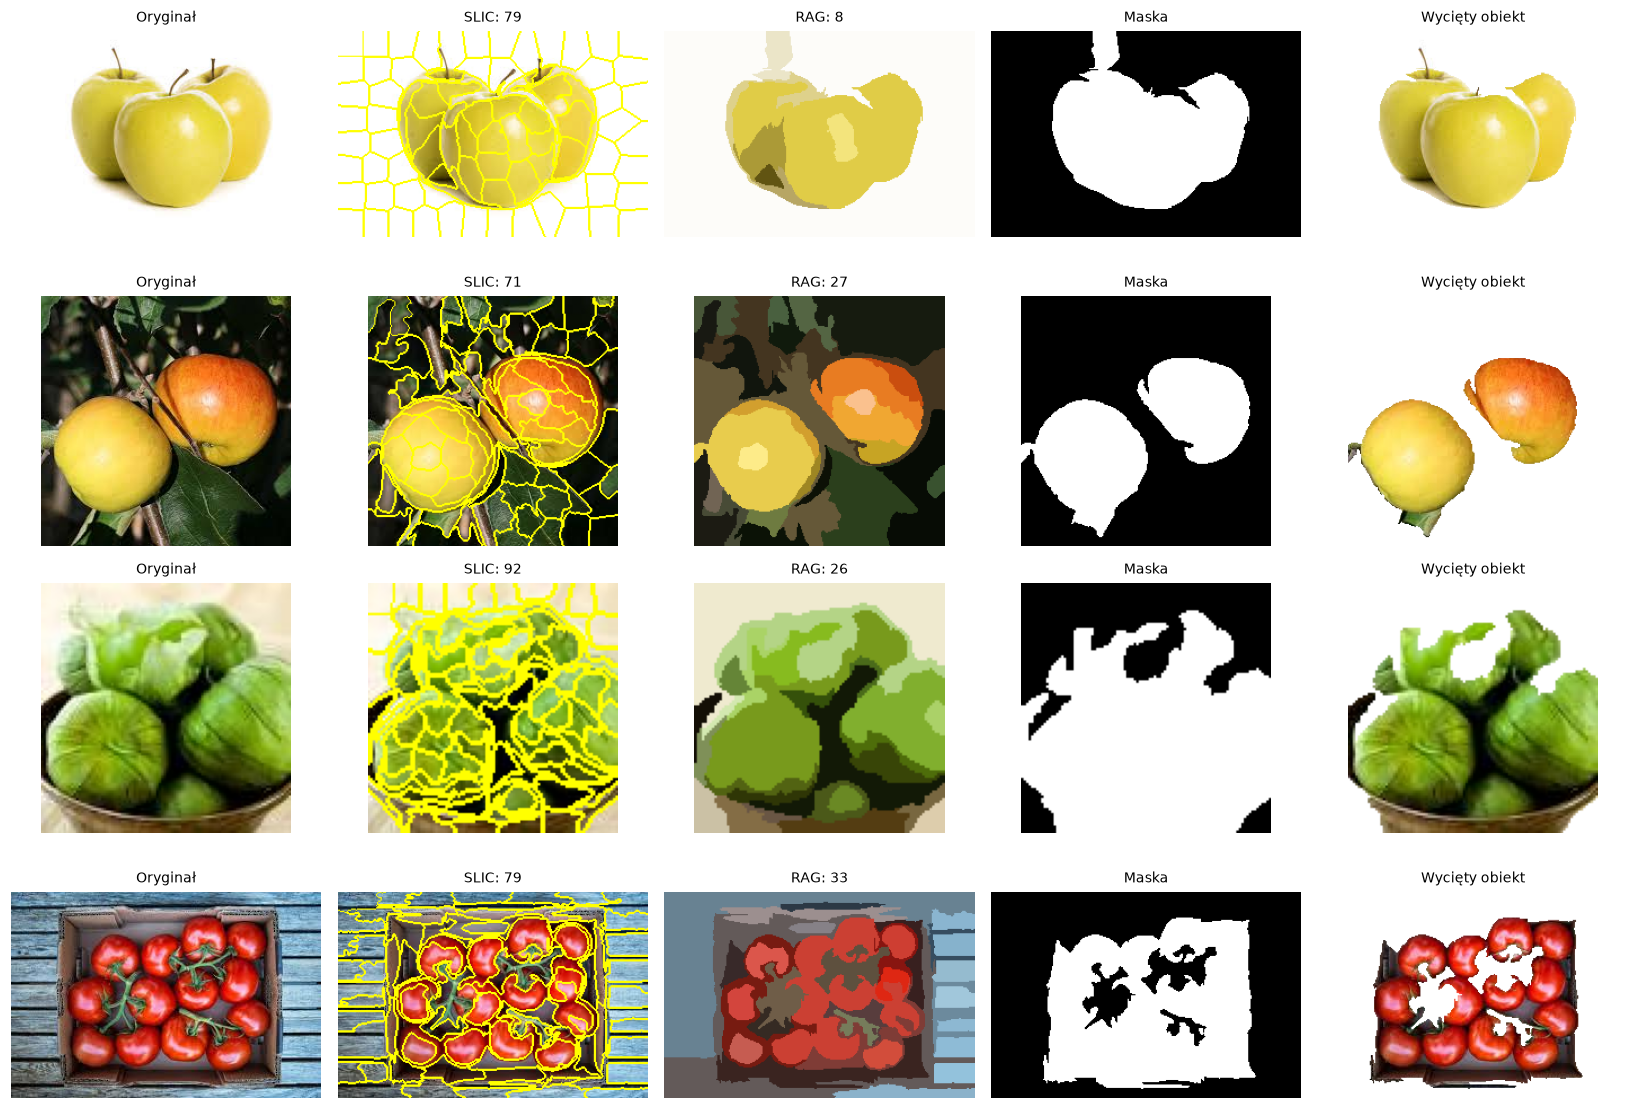

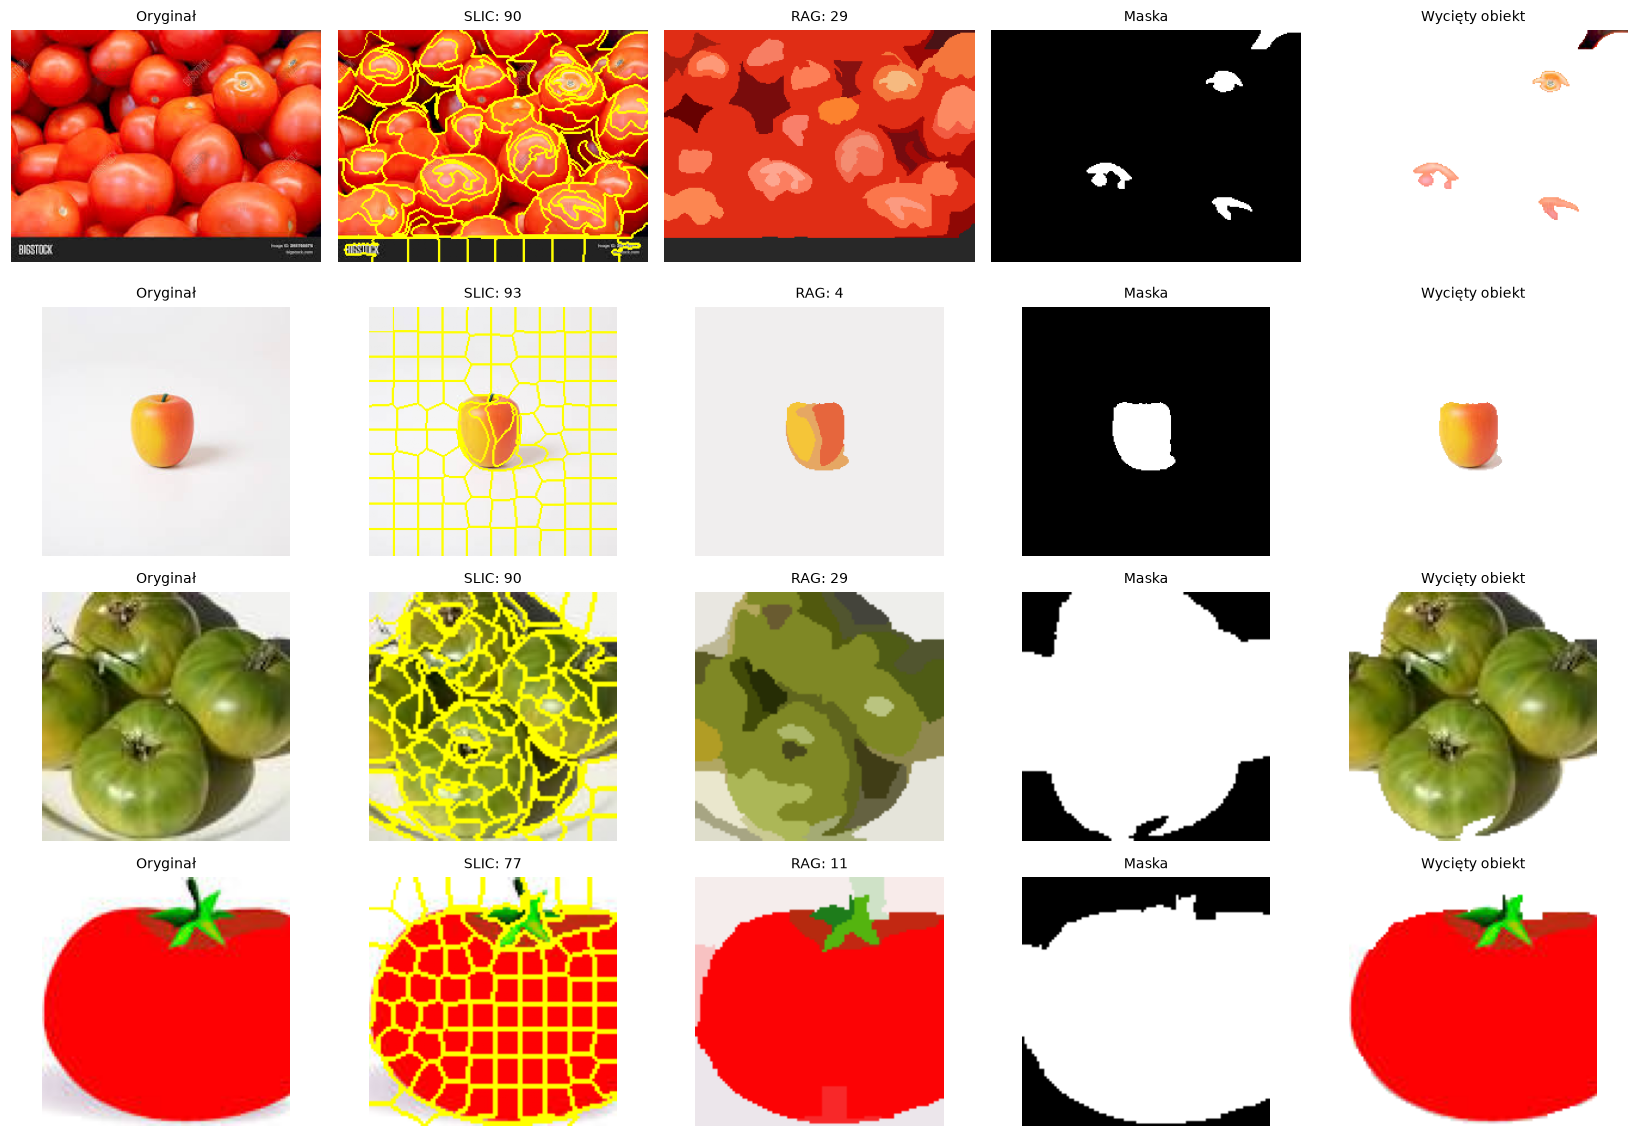

In [16]:
def show_slic_stages(sources,filename):
    fig,axes=plt.subplots(len(sources),5,figsize=(15,2.6*len(sources)),squeeze=False)
    for axs,source in zip(axes,sources):
        rgb=read_rgb(DATA/source)
        mask,info,(img,labels,merged)=slic_rag_segment(rgb,details=True)
        cut=np.full_like(rgb,255);cut[mask]=rgb[mask]
        views=[rgb,mark_boundaries(img,labels),label2rgb(merged,img,kind='avg',bg_label=-1),mask,cut]
        titles=['Oryginał',f'SLIC: {info["superpixels"]}',f'RAG: {info["regions"]}','Maska','Wycięty obiekt']
        for ax,im,title in zip(axs,views,titles):
            ax.imshow(im,cmap='gray' if im.ndim==2 else None);ax.axis('off');ax.set_title(title,fontsize=9)
    plt.tight_layout();plt.savefig(SLICOUT/filename,bbox_inches='tight');plt.show()
show_slic_stages(fixed,'slic_rag_stages.png')
train_diag=slic_diag[slic_diag.split=='train']
extremes=pd.concat([train_diag.nsmallest(2,'foreground_fraction'),train_diag.nlargest(2,'foreground_fraction')]).drop_duplicates('source')
show_slic_stages(extremes.source.tolist(),'extreme_masks_train.png')


## 8.3. Klasyfikacja tekstur i porównanie trzech wariantów
Identyczna deduplikacja, kontrola sprzecznych etykiet, foldy i siatka SVM. Puste maski nie są usuwane; brakujące cechy imputujemy wewnątrz pipeline na podstawie danych treningowych.

Sprzecznie opisane obrazy: 2 w grupach: 1


,source,label
50,test/apples/img_p3_79.jpeg,apples
277,train/tomatoes/img_p1_28.jpeg,tomatoes


Po usunięciu duplikatów: train = 283 test = 84


label,apples,tomatoes
split,,
test,44,40
train,156,127


,features,cv_balanced_accuracy,cv_std,params
0,LBP,0.724833,0.062258,"{'svm__C': 10, 'svm__gamma': 'scale'}"
2,LBP + GLCM,0.720035,0.059603,"{'svm__C': 1, 'svm__gamma': 'scale'}"
1,GLCM,0.699823,0.026100,"{'svm__C': 100, 'svm__gamma': 0.01}"


,model,accuracy,balanced_accuracy,f1_macro
0,Dummy: najczęstsza klasa,0.52381,0.500000,0.343750
1,SVM / LBP,0.72619,0.730682,0.725217


              precision    recall  f1-score   support

      apples       0.80      0.64      0.71        44
    tomatoes       0.67      0.82      0.74        40

    accuracy                           0.73        84
   macro avg       0.74      0.73      0.73        84
weighted avg       0.74      0.73      0.72        84



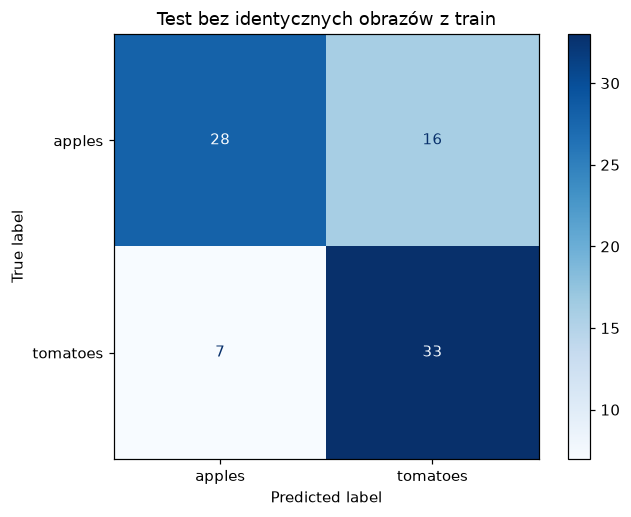

Wybrany wariant: LBP | Parametry: {'svm__C': 10, 'svm__gamma': 'scale'}


In [17]:
def evaluate_slic_rag():
    conflicts=slic_textures.groupby('pixel_hash').label.nunique()
    conflict_hashes=set(conflicts[conflicts>1].index)
    conflict_rows=slic_textures[slic_textures.pixel_hash.isin(conflict_hashes)]
    print('Sprzecznie opisane obrazy:',len(conflict_rows),'w grupach:',len(conflict_hashes))
    display(conflict_rows[['source','label']])
    conflict_rows.to_csv(SLICOUT/'texture_label_conflicts.csv',index=False)
    clean=slic_textures[~slic_textures.pixel_hash.isin(conflict_hashes)]
    tr=clean[clean.split=='train'].drop_duplicates('pixel_hash').copy()
    te=clean[clean.split=='test'].drop_duplicates('pixel_hash').copy()
    te=te[~te.pixel_hash.isin(tr.pixel_hash)].copy()
    assert not set(tr.pixel_hash)&set(te.pixel_hash)
    
    print('Po usunięciu duplikatów: train =',len(tr),'test =',len(te))
    display(pd.crosstab(pd.concat([tr,te])['split'],pd.concat([tr,te])['label']))
    sets={'LBP':[c for c in feature_cols if c.startswith('lbp_')],
          'GLCM':[c for c in feature_cols if c.startswith('glcm_')],
          'LBP + GLCM':feature_cols}
    cv=list(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED).split(tr,tr.label,tr.pixel_hash))
    searches={}; scores=[]
    for name,cols in sets.items():
        pipe=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                       ('scale',StandardScaler()),('svm',SVC(class_weight='balanced'))])
        search=GridSearchCV(pipe,{'svm__C':[.1,1,10,100], 'svm__gamma':['scale',.01,.1]},
                            scoring='balanced_accuracy',cv=cv,n_jobs=1)
        search.fit(tr[cols],tr.label)
        searches[name]=search
        scores.append(dict(features=name,cv_balanced_accuracy=search.best_score_,
                           cv_std=search.cv_results_['std_test_score'][search.best_index_],params=str(search.best_params_)))
    comparison=pd.DataFrame(scores).sort_values('cv_balanced_accuracy',ascending=False)
    display(comparison)
    best_name=comparison.iloc[0]['features']; best=searches[best_name]; cols=sets[best_name]
    pred=best.predict(te[cols])
    dummy=DummyClassifier(strategy='most_frequent').fit(tr[cols],tr.label)
    baseline=dummy.predict(te[cols])
    results=pd.DataFrame([dict(model='Dummy: najczęstsza klasa',accuracy=accuracy_score(te.label,baseline),
                               balanced_accuracy=balanced_accuracy_score(te.label,baseline),f1_macro=f1_score(te.label,baseline,average='macro')),
                          dict(model='SVM / '+best_name,accuracy=accuracy_score(te.label,pred),
                               balanced_accuracy=balanced_accuracy_score(te.label,pred),f1_macro=f1_score(te.label,pred,average='macro'))])
    display(results)
    print(classification_report(te.label,pred,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(te.label,pred,cmap='Blues'); plt.title('Test bez identycznych obrazów z train'); plt.tight_layout()
    plt.savefig(SLICOUT/'texture_confusion_matrix.png',bbox_inches='tight'); plt.show()
    comparison.to_csv(SLICOUT/'texture_cv_results.csv',index=False)
    results.to_csv(SLICOUT/'texture_test_metrics.csv',index=False)
    predictions=te[['source','label','interior_pixels']].copy(); predictions['prediction']=pred
    predictions.to_csv(SLICOUT/'texture_test_predictions.csv',index=False)
    print('Wybrany wariant:',best_name,'| Parametry:',best.best_params_)
    return results, comparison, predictions

slic_results,slic_cv,slic_predictions=evaluate_slic_rag()


In [18]:
all_comparison=pd.concat([comparison_final,slic_results.assign(segmentation='SLIC + RAG')],ignore_index=True)
display(all_comparison)
all_comparison.to_csv(SLICOUT/'all_methods_comparison.csv',index=False)
assert slic_predictions.source.tolist()==hybrid_predictions.source.tolist()
print('Test obejmuje te same',len(slic_predictions),'obrazów dla wszystkich metod.')
(SLICROOT/'README.md').write_text('Segmentacja SLIC + RAG z sekcji 8 task3.ipynb.\n'
    'images/: PNG RGBA; masks/: maski 0/255; manifest.csv: diagnostyka i źródła.\n'
    'Parametry: 200 superpikseli, compactness=10, sigma=1, próg scalania RAG=15 w Lab.\n'
    'Wybór obiektu: odległość koloru regionu od tła + Otsu, filtr kontaktu z brzegiem i małych składowych.\n'
    'Puste maski pozostają puste. Brak gwarancji semantycznej poprawności.\n')


,model,accuracy,balanced_accuracy,f1_macro,segmentation
0,Dummy: najczęstsza klasa,0.523810,0.500000,0.343750,Lab
1,SVM / LBP + GLCM,0.773810,0.771591,0.772228,Lab
2,Dummy: najczęstsza klasa,0.523810,0.500000,0.343750,Kolor + kształt
3,SVM / LBP + GLCM,0.690476,0.694318,0.689773,Kolor + kształt
4,Dummy: najczęstsza klasa,0.523810,0.500000,0.343750,SLIC + RAG
5,SVM / LBP,0.726190,0.730682,0.725217,SLIC + RAG


Test obejmuje te same 84 obrazów dla wszystkich metod.


377

## 8.4. Wyniki i ograniczenia
Przetworzono **391 zdjęć** i zapisano po jednej masce i jednym obrazie RGBA w `segmented_dataset_slic_rag/`. Żadna końcowa maska nie była całkowicie pusta. Mediana liczby regionów po scaleniu: **27 na train, 26 na test**. Brak pustych masek nie oznacza ich poprawności.

Najlepszy wariant walidacyjny to **GLCM + SVM RBF**, C=100, gamma=0.01. Balanced accuracy walidacji: **74,0% ± 5,8 p.p.** (odchylenie między foldami). Test po identycznym oczyszczeniu obejmuje **84 obrazy**.

| Segmentacja | Accuracy test | Balanced accuracy test |
|---|---:|---:|
| Lab + Otsu | 77,4% (65/84) | 77,2% |
| Kolor + kształt | 69,0% (58/84) | 69,4% |
| SLIC + RAG | **76,2% (64/84)** | **76,1%** |

Macro F1 SLIC/RAG: **76,1%**. Różnica accuracy względem Lab to tylko jedna poprawna odpowiedź na tym teście; nie traktujemy tego jako mocnego dowodu przewagi którejkolwiek metody.

Na pokazanych przykładach SLIC/RAG zachowuje oba jabłka na gałęzi i lepiej wydziela pomidory ze skrzynki niż hybryda kształtu. Pozostają fragmenty gałęzi i miski, a jasne refleksy bywają wycinane. Gdy owoc ma podobny kolor do tła lub dotyka brzegu, reguła wyboru regionów może go zgubić. Scalanie RAG może również połączyć owoc z tłem.

**Ważne:** tekstury liczymy na oryginalnych pikselach wewnątrz maski, nie na obrazie uśrednionych kolorów RAG z wizualizacji. To utrzymuje porównywalność z wcześniejszymi metodami.

Maski i obrazy: `segmented_dataset_slic_rag/`. Cechy, predykcje, macierz pomyłek i porównanie trzech metod: `outputs/slic_rag/`. Do obiektywnej oceny segmentacji nadal potrzebne są ręczne maski wzorcowe.


# 9. Tuning parametrów segmentacji — wyłącznie na train
Nie mamy masek wzorcowych. Optymalizujemy więc **użyteczność segmentacji dla klasyfikacji tekstur**, nie IoU ani wizualną poprawność. Dla wszystkich kandydatów używamy tych samych 34 cech LBP/GLCM oraz tego samego pipeline: imputacja, standaryzacja, SVM RBF (C=1, gamma=scale, class_weight=balanced). Parametry klasyfikatora są stałe, aby porównanie dotyczyło segmentacji.

Każda metoda ma 8 kombinacji parametrów oraz swój wariant bazowy. Kandydatów oceniamy przez identyczną 5-fold walidację train, wybierając najwyższą średnią balanced accuracy. Podajemy też **zagnieżdżoną walidację 3×3** całej procedury wyboru parametrów, aby ograniczyć optymizm wynikający z wyboru najlepszego z wielu wariantów.

Wykorzystujemy ten sam oczyszczony train co wcześniej (283 obrazy); identyczne obrazy nie przechodzą między foldami. Znane sprzeczne etykiety pozostają wyłączone. Żadna etykieta testowa ani wynik testowy nie uczestniczy w przeszukiwaniu. Wyniki poprzednich testów były już widoczne, więc ostateczne potwierdzenie wymaga nowego zbioru.

**Zakres:** Lab — szerokość pasa tła, mnożnik progu Otsu, rozmiar morfologii; hybryda — minimalny udział kandydata w obrazie, poparcie koloru, próg oceny kształtu; SLIC/RAG — liczba superpikseli, compactness i próg scalania. Pozostałe reguły pozostają stałe. To ograniczona siatka, nie poszukiwanie globalnego optimum.

Baza SLIC odpowiada bieżącej wersji notebooka: **100 superpikseli**, compactness=10, próg RAG=15. Porównanie w tej sekcji przelicza bazę i kandydatów na tych samych danych.

In [19]:
def clean_mask_tuned(mask, morph_ratio=.012):
    mask = mask.astype(np.uint8)*255
    k = max(3, int(round(min(mask.shape)*morph_ratio)) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k,k))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = np.zeros_like(mask)
    if contours: cv2.drawContours(out, [max(contours,key=cv2.contourArea)], -1, 255, -1)
    return out > 0

def segment_lab_tuned(rgb, border_ratio=.04, threshold_factor=1., morph_ratio=.012):
    method='lab'
    # Wspólna skala robocza ogranicza koszt i stabilizuje morfologię.
    h,w = rgb.shape[:2]
    scale = min(1, 384/max(h,w))
    small = cv2.resize(rgb, (max(1,round(w*scale)),max(1,round(h*scale))))
    if method == 'hsv':
        hsv = cv2.cvtColor(small, cv2.COLOR_RGB2HSV)
        raw = (hsv[:,:,1] > 55) & (hsv[:,:,2] > 35)
    else:
        lab = cv2.cvtColor(small, cv2.COLOR_RGB2LAB).astype(np.float32)
        b = max(1, round(min(lab.shape[:2])*border_ratio))
        border = np.concatenate([lab[:b].reshape(-1,3), lab[-b:].reshape(-1,3),
                                 lab[:,:b].reshape(-1,3), lab[:,-b:].reshape(-1,3)])
        background = np.median(border, axis=0)
        distance = np.linalg.norm(lab-background, axis=2)
        distance = np.uint8(np.clip(distance,0,255))
        threshold, _ = cv2.threshold(distance,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
        raw = distance > threshold*threshold_factor
    cleaned = clean_mask_tuned(raw, morph_ratio)
    return cv2.resize(cleaned.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST).astype(bool)


def segment_hybrid_tuned(rgb, min_area=.008, color_support_threshold=.45, shape_threshold=.57):
    h,w=rgb.shape[:2]; scale=min(1,384/max(h,w))
    img=cv2.resize(rgb,(max(1,round(w*scale)),max(1,round(h*scale))))
    hh,ww=img.shape[:2]; area_image=hh*ww
    lab=cv2.cvtColor(img,cv2.COLOR_RGB2LAB).astype(np.float32)
    b=max(1,round(min(hh,ww)*.04))
    border=np.concatenate([lab[:b].reshape(-1,3),lab[-b:].reshape(-1,3),lab[:,:b].reshape(-1,3),lab[:,-b:].reshape(-1,3)])
    distance=np.uint8(np.clip(np.linalg.norm(lab-np.median(border,axis=0),axis=2),0,255))
    _,lab_raw=cv2.threshold(distance,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    hsv=cv2.cvtColor(img,cv2.COLOR_RGB2HSV)
    hsv_raw=np.uint8((hsv[:,:,1]>55)&(hsv[:,:,2]>35))*255
    color_support=(lab_raw>0)|(hsv_raw>0)
    gray=cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)
    edges=cv2.Canny(cv2.GaussianBlur(gray,(5,5),0),50,140)
    kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))
    candidates=[]
    for source,raw in [('lab',lab_raw),('hsv',hsv_raw),('edges',edges)]:
        raw=cv2.morphologyEx(raw,cv2.MORPH_CLOSE,kernel,iterations=2)
        contours,_=cv2.findContours(raw,cv2.RETR_LIST,cv2.CHAIN_APPROX_SIMPLE)
        for contour in contours:
            area=cv2.contourArea(contour); perimeter=cv2.arcLength(contour,True)
            if area < max(25,min_area*area_image) or area>.85*area_image or perimeter==0: continue
            x,y,cw,ch=cv2.boundingRect(contour)
            ratio=min(cw,ch)/max(cw,ch)
            circularity=min(1,4*np.pi*area/perimeter**2)
            hull_area=cv2.contourArea(cv2.convexHull(contour))
            solidity=area/max(hull_area,1)
            if ratio<.35 or circularity<.25 or solidity<.65: continue
            mask=np.zeros((hh,ww),np.uint8); cv2.drawContours(mask,[contour],-1,1,-1)
            mask=mask.astype(bool)
            support=float(color_support[mask].mean())
            if support<color_support_threshold: continue
            ellipse_iou=0.
            if len(contour)>=5:
                ellipse=cv2.fitEllipse(contour)
                ellipse_mask=np.zeros((hh,ww),np.uint8)
                cv2.ellipse(ellipse_mask,ellipse,1,-1)
                e=ellipse_mask>0
                ellipse_iou=float((mask&e).sum()/max(1,(mask|e).sum()))
            touch=float(np.concatenate([mask[0],mask[-1],mask[:,0],mask[:,-1]]).mean())
            score=.30*circularity+.25*solidity+.15*ratio+.20*ellipse_iou+.10*support-.30*touch
            if score>=shape_threshold:
                candidates.append((score,area,mask,source))
    # Duplikaty kandydatów i kontury zagnieżdżone nie dodają nowych obiektów.
    candidates.sort(key=lambda x:(x[0],x[1]),reverse=True)
    selected=[]; combined=np.zeros((hh,ww),bool)
    for score,area,mask,source in candidates:
        if (mask&combined).sum()/max(1,mask.sum())>.25: continue
        selected.append((score,source)); combined |= mask
    fallback=not bool(selected)
    result=segment(rgb,'lab') if fallback else cv2.resize(combined.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST)>0
    return result,dict(fallback=fallback,objects=len(selected),best_shape_score=selected[0][0] if selected else np.nan)


def segment_slic_tuned(rgb, n_segments=100, compactness=10, merge_threshold=15, details=False):
    h,w=rgb.shape[:2]; scale=min(1,384/max(h,w))
    img=cv2.resize(rgb,(max(1,round(w*scale)),max(1,round(h*scale))))
    labels=slic(img,n_segments=n_segments,compactness=compactness,sigma=1,start_label=0,
                convert2lab=True,enforce_connectivity=True,channel_axis=-1)
    lab=rgb2lab(img)
    rag=graph.rag_mean_color(lab,labels,connectivity=2,mode='distance')
    merged=graph.merge_hierarchical(labels,rag,thresh=merge_threshold,rag_copy=False,
                in_place_merge=True,merge_func=merge_region_color,weight_func=region_weight)
    hh,ww=merged.shape; b=max(1,round(min(hh,ww)*.04))
    border=np.concatenate([lab[:b].reshape(-1,3),lab[-b:].reshape(-1,3),lab[:,:b].reshape(-1,3),lab[:,-b:].reshape(-1,3)])
    background=np.median(border,axis=0)
    count=np.bincount(merged.ravel())
    means=np.column_stack([np.bincount(merged.ravel(),weights=lab[:,:,k].ravel())/np.maximum(count,1) for k in range(3)])
    distance=np.linalg.norm(means-background,axis=1)
    # Skalowanie całej mapy do uint8 jedynie na potrzeby implementacji Otsu.
    score=distance[merged]
    scaled=np.uint8(np.clip(score/max(float(score.max()),1e-8)*255,0,255))
    threshold,_=cv2.threshold(scaled,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    region_score=distance/max(float(score.max()),1e-8)*255
    edge_labels=np.concatenate([merged[0],merged[-1],merged[:,0],merged[:,-1]])
    edge_fraction=np.bincount(edge_labels,minlength=len(count))/len(edge_labels)
    foreground=(region_score>threshold)&(edge_fraction<=.25)
    mask=foreground[merged].astype(np.uint8)
    ncomp,components,stats,_=cv2.connectedComponentsWithStats(mask,8)
    keep=np.zeros(ncomp,bool)
    if ncomp>1: keep[1:]=stats[1:,cv2.CC_STAT_AREA]>=max(9,.005*hh*ww)
    mask=keep[components]
    full=cv2.resize(mask.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST)>0
    info=dict(superpixels=int(np.unique(labels).size),regions=int(np.unique(merged).size),
              foreground_fraction=float(full.mean()),empty=not bool(full.any()))
    if details: return full,info,(img,labels,merged)
    return full,info



In [20]:
from itertools import product
from sklearn.model_selection import cross_val_score
import time
TUNEOUT=OUT/'segmentation_tuning';TUNEOUT.mkdir(parents=True,exist_ok=True)
TUNEROOT=ROOT/'segmented_dataset_tuned'

def make_configs(keys,values,baseline):
    configs=[dict(zip(keys,v)) for v in product(*values)]
    configs.insert(0,baseline)
    return configs
configs={
 'lab':make_configs(['border_ratio','threshold_factor','morph_ratio'],
                    [[.02,.08],[.8,1.2],[.006,.02]],
                    dict(border_ratio=.04,threshold_factor=1.,morph_ratio=.012)),
 'hybrid':make_configs(['min_area','color_support_threshold','shape_threshold'],
                    [[.003,.015],[.3,.6],[.50,.65]],
                    dict(min_area=.008,color_support_threshold=.45,shape_threshold=.57)),
 'slic_rag':make_configs(['n_segments','compactness','merge_threshold'],
                    [[100,250],[5,15],[10,25]],
                    dict(n_segments=100,compactness=10,merge_threshold=15))}
segmenters={'lab':segment_lab_tuned,'hybrid':segment_hybrid_tuned,'slic_rag':segment_slic_tuned}
# Dokładnie te same obrazy train i kolejność we wszystkich metodach.
tuning_train=tr.reset_index(drop=True).copy()
assert len(tuning_train)==283 and (tuning_train.split=='train').all()
train_images=[read_rgb(DATA/source) for source in tuning_train.source]
y_tune=tuning_train.label.to_numpy();groups_tune=tuning_train.pixel_hash.to_numpy()
splits5=list(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED).split(tuning_train,y_tune,groups_tune))

def fixed_texture_classifier():
    return Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                     ('scale',StandardScaler()),('svm',SVC(C=1,gamma='scale',class_weight='balanced'))])

def tuned_mask(method,rgb,params):
    output=segmenters[method](rgb,**params)
    return output if method=='lab' else output[0]

# Baseline parametryzowanych funkcji musi dawać maski identyczne z poprzednimi.
for method,oldroot in [('lab',SEG),('hybrid',HYBROOT),('slic_rag',SLICROOT)]:
    for i in (0,50,100):
        source=tuning_train.iloc[i].source
        with Image.open(oldroot/'masks'/(source+'.png')) as im: previous=np.array(im)>0
        assert np.array_equal(tuned_mask(method,train_images[i],configs[method][0]),previous),method

# Parametry muszą rzeczywiście zmieniać podział SLIC na kontrolnym obrazie.
_,_,(_,few,_)=segment_slic_tuned(train_images[0],n_segments=100,details=True)
_,_,(_,many,_)=segment_slic_tuned(train_images[0],n_segments=250,details=True)
assert np.unique(few).size != np.unique(many).size

tuning_train[['source','label','pixel_hash']].to_csv(TUNEOUT/'train_feature_order.csv',index=False)
feature_cache={}; tuning_rows=[]
for method,candidates in configs.items():
    feature_cache[method]=[]
    for index,params in enumerate(candidates):
        start=time.perf_counter();features=[];fractions=[];missing=0
        for rgb in train_images:
            mask=tuned_mask(method,rgb,params)
            f,interior=texture_features(rgb,mask)
            features.append([f[c] for c in feature_cols]);fractions.append(mask.mean());missing+=int(interior==0)
        X=np.asarray(features,dtype=float)
        feature_cache[method].append(X)
        scores=cross_val_score(fixed_texture_classifier(),X,y_tune,cv=splits5,scoring='balanced_accuracy',n_jobs=1)
        tuning_rows.append(dict(method=method,candidate=index,baseline=index==0,params=json.dumps(params),
            cv_balanced_accuracy=float(scores.mean()),cv_std=float(scores.std()),
            no_lbp_neighborhood=missing,mean_mask_fraction=float(np.mean(fractions)),seconds=time.perf_counter()-start))
        pd.DataFrame(tuning_rows).to_csv(TUNEOUT/'search_results.csv',index=False)
        print(f'{method} {index+1}/{len(candidates)}: CV={scores.mean():.3f}',flush=True)
    np.savez_compressed(TUNEOUT/f'{method}_train_features.npz',**{f'candidate_{i}':X for i,X in enumerate(feature_cache[method])})
tuning_results=pd.DataFrame(tuning_rows)
best_configs={}
for method in configs:
    ranked=tuning_results[tuning_results.method==method].sort_values(['cv_balanced_accuracy','candidate'],ascending=[False,True])
    best_configs[method]=int(ranked.iloc[0].candidate)
    display(ranked[['candidate','baseline','params','cv_balanced_accuracy','cv_std','no_lbp_neighborhood']])


lab 1/9: CV=0.687


lab 2/9: CV=0.710


lab 3/9: CV=0.698


lab 4/9: CV=0.710


lab 5/9: CV=0.719


...

slic_rag 8/9: CV=0.704


slic_rag 9/9: CV=0.692


,candidate,baseline,params,cv_balanced_accuracy,cv_std,no_lbp_neighborhood
4,4,False,"{""border_ratio"": 0.02, ""threshold_factor"": 1.2...",0.718775,0.043685,0
7,7,False,"{""border_ratio"": 0.08, ""threshold_factor"": 1.2...",0.715165,0.074059,0
8,8,False,"{""border_ratio"": 0.08, ""threshold_factor"": 1.2...",0.714699,0.055561,0
1,1,False,"{""border_ratio"": 0.02, ""threshold_factor"": 0.8...",0.710300,0.017685,0
3,3,False,"{""border_ratio"": 0.02, ""threshold_factor"": 1.2...",0.709925,0.055340,0
5,5,False,"{""border_ratio"": 0.08, ""threshold_factor"": 0.8...",0.700131,0.024367,0
2,2,False,"{""border_ratio"": 0.02, ""threshold_factor"": 0.8...",0.697578,0.025819,0
6,6,False,"{""border_ratio"": 0.08, ""threshold_factor"": 0.8...",0.690507,0.045546,0
0,0,True,"{""border_ratio"": 0.04, ""threshold_factor"": 1.0...",0.687339,0.027082,0


,candidate,baseline,params,cv_balanced_accuracy,cv_std,no_lbp_neighborhood
16,7,False,"{""min_area"": 0.015, ""color_support_threshold"":...",0.717069,0.037298,0
11,2,False,"{""min_area"": 0.003, ""color_support_threshold"":...",0.698554,0.044465,0
14,5,False,"{""min_area"": 0.015, ""color_support_threshold"":...",0.693377,0.041275,0
15,6,False,"{""min_area"": 0.015, ""color_support_threshold"":...",0.691882,0.029670,0
13,4,False,"{""min_area"": 0.003, ""color_support_threshold"":...",0.689243,0.036600,0
12,3,False,"{""min_area"": 0.003, ""color_support_threshold"":...",0.685243,0.021370,0
10,1,False,"{""min_area"": 0.003, ""color_support_threshold"":...",0.684468,0.028185,0
9,0,True,"{""min_area"": 0.008, ""color_support_threshold"":...",0.681714,0.013062,0
17,8,False,"{""min_area"": 0.015, ""color_support_threshold"":...",0.679752,0.030170,0


,candidate,baseline,params,cv_balanced_accuracy,cv_std,no_lbp_neighborhood
24,6,False,"{""n_segments"": 250, ""compactness"": 5, ""merge_t...",0.726048,0.045987,2
21,3,False,"{""n_segments"": 100, ""compactness"": 15, ""merge_...",0.720698,0.068698,0
18,0,True,"{""n_segments"": 100, ""compactness"": 10, ""merge_...",0.720035,0.059603,0
23,5,False,"{""n_segments"": 250, ""compactness"": 5, ""merge_t...",0.706015,0.063721,0
25,7,False,"{""n_segments"": 250, ""compactness"": 15, ""merge_...",0.704232,0.044562,0
19,1,False,"{""n_segments"": 100, ""compactness"": 5, ""merge_t...",0.702118,0.054709,0
22,4,False,"{""n_segments"": 100, ""compactness"": 15, ""merge_...",0.694636,0.035590,2
26,8,False,"{""n_segments"": 250, ""compactness"": 15, ""merge_...",0.692232,0.034800,2
20,2,False,"{""n_segments"": 100, ""compactness"": 5, ""merge_t...",0.677835,0.059839,3


## 9.1. Zagnieżdżona walidacja doboru segmentacji
W każdym z trzech zewnętrznych foldów wybieramy konfigurację na trzech foldach wewnętrznych, a następnie oceniamy ją na niewidzianym foldzie zewnętrznym. Bazowy i dobrany wariant mają ten sam klasyfikator i identyczne foldy. Ekstrakcja cech może być buforowana, bo nie uczy się niczego między zdjęciami; imputacja i standaryzacja są zawsze dopasowywane wewnątrz foldów.

In [21]:
outer=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED+1).split(tuning_train,y_tune,groups_tune))
nested_rows=[]
for method in configs:
    for fold,(fit_idx,val_idx) in enumerate(outer,1):
        inner=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED+2).split(
            fit_idx,y_tune[fit_idx],groups_tune[fit_idx]))
        inner_scores=[]
        for X in feature_cache[method]:
            inner_scores.append(cross_val_score(fixed_texture_classifier(),X[fit_idx],y_tune[fit_idx],
                cv=inner,scoring='balanced_accuracy',n_jobs=1).mean())
        chosen=int(np.argmax(inner_scores))
        for label,index in [('baseline',0),('tuned',chosen)]:
            X=feature_cache[method][index]
            model=fixed_texture_classifier().fit(X[fit_idx],y_tune[fit_idx])
            prediction=model.predict(X[val_idx])
            nested_rows.append(dict(method=method,fold=fold,variant=label,candidate=index,
                balanced_accuracy=balanced_accuracy_score(y_tune[val_idx],prediction)))
nested_results=pd.DataFrame(nested_rows)
nested_results.to_csv(TUNEOUT/'nested_validation.csv',index=False)
display(nested_results.groupby(['method','variant']).balanced_accuracy.agg(['mean','std']))
selected_rows=[]
for method,index in best_configs.items():
    baseline=tuning_results[(tuning_results.method==method)&(tuning_results.candidate==0)].iloc[0]
    best=tuning_results[(tuning_results.method==method)&(tuning_results.candidate==index)].iloc[0]
    selected_rows.append(dict(method=method,candidate=index,params=best.params,
        baseline_cv=baseline.cv_balanced_accuracy,selected_cv=best.cv_balanced_accuracy,
        delta_pp=100*(best.cv_balanced_accuracy-baseline.cv_balanced_accuracy)))
selected_parameters=pd.DataFrame(selected_rows)
display(selected_parameters)
selected_parameters.to_csv(TUNEOUT/'selected_parameters.csv',index=False)
(TUNEOUT/'selected_parameters.json').write_text(json.dumps({m:configs[m][i] for m,i in best_configs.items()},indent=2))


mean       std
method   variant                     
hybrid   baseline  0.683125  0.037580
         tuned     0.679920  0.030180
lab      baseline  0.682824  0.062115
         tuned     0.696801  0.048467
slic_rag baseline  0.685507  0.062420
         tuned     0.662645  0.046767

,method,candidate,params,baseline_cv,selected_cv,delta_pp
0,lab,4,"{""border_ratio"": 0.02, ""threshold_factor"": 1.2...",0.687339,0.718775,3.143610
1,hybrid,7,"{""min_area"": 0.015, ""color_support_threshold"":...",0.681714,0.717069,3.535484
2,slic_rag,6,"{""n_segments"": 250, ""compactness"": 5, ""merge_t...",0.720035,0.726048,0.601334


294

## 9.2. Eksport dobranych segmentacji i porównanie wizualne na train
Konfiguracje wybrane wyłącznie na train stosujemy do wszystkich obrazów, zapisując osobny folder dla każdej metody. Sam eksport testu nie wykorzystuje jego etykiet ani nie oblicza wyniku klasyfikacji. Wcześniejsze foldery pozostają bez zmian.

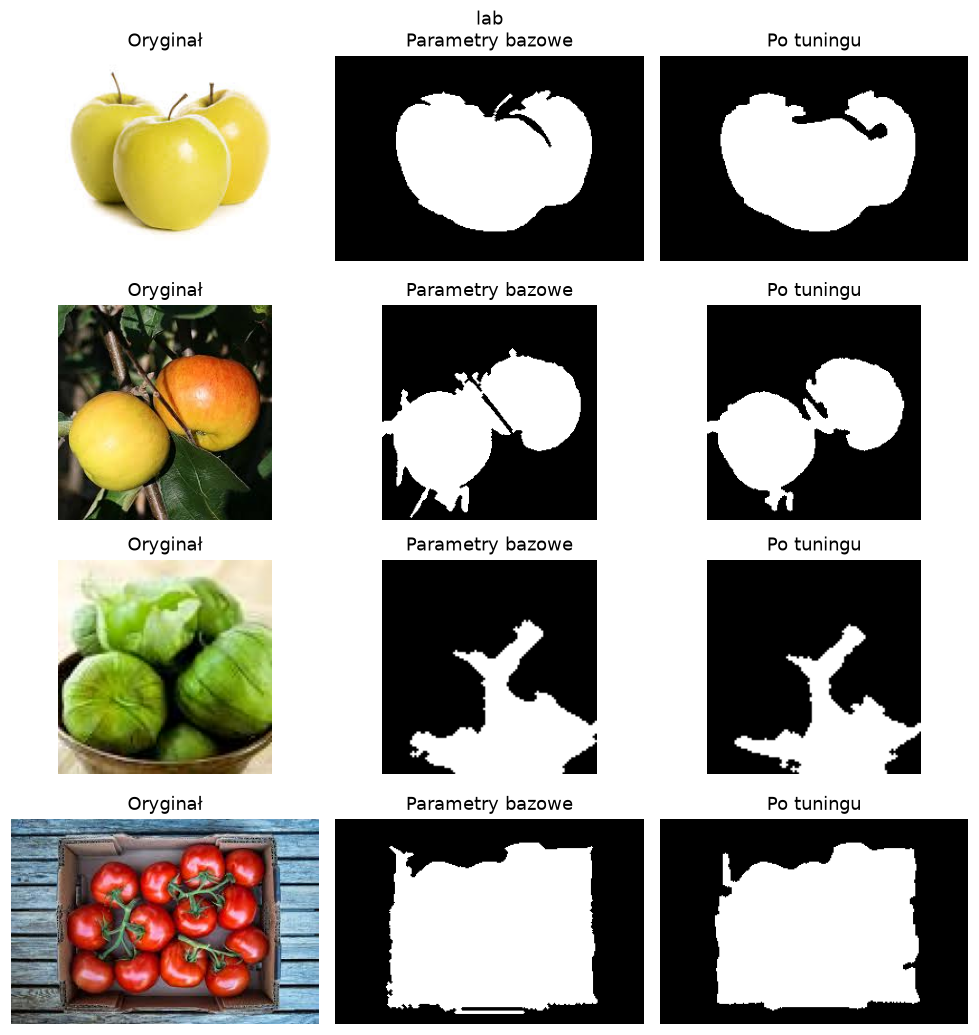

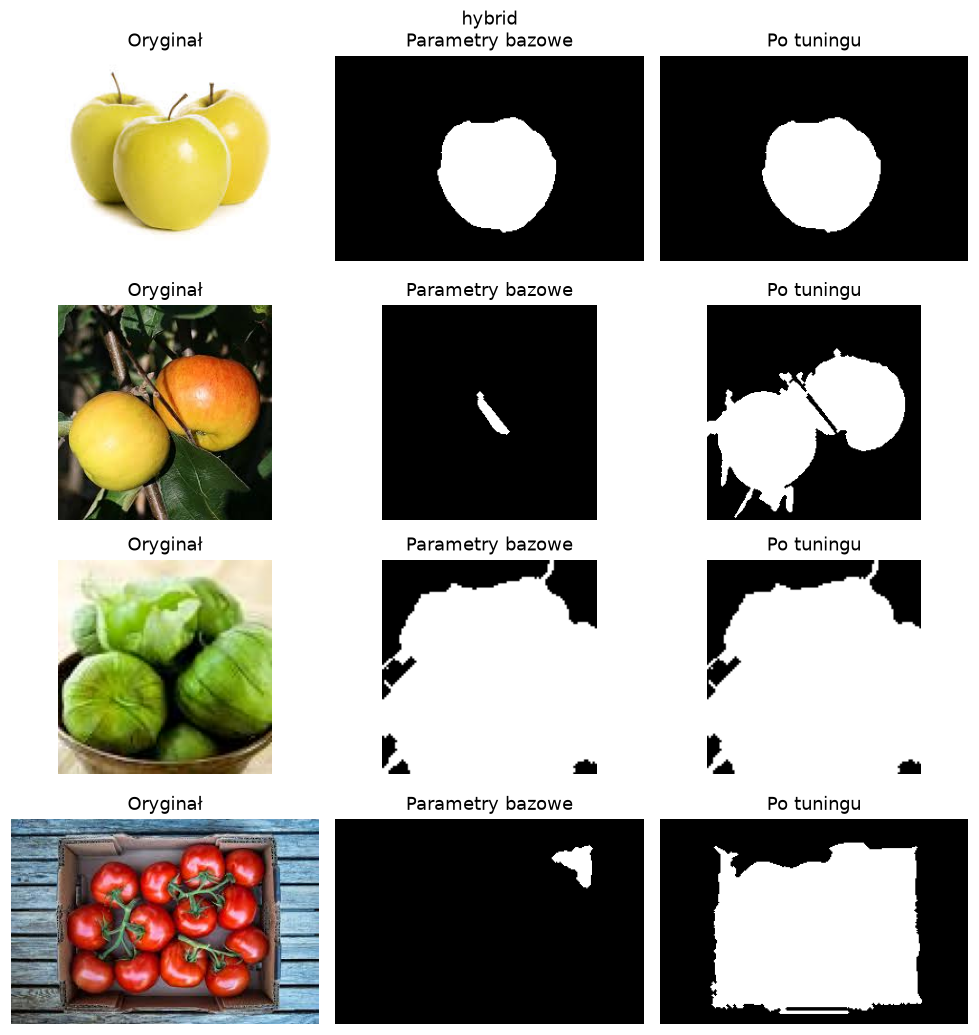

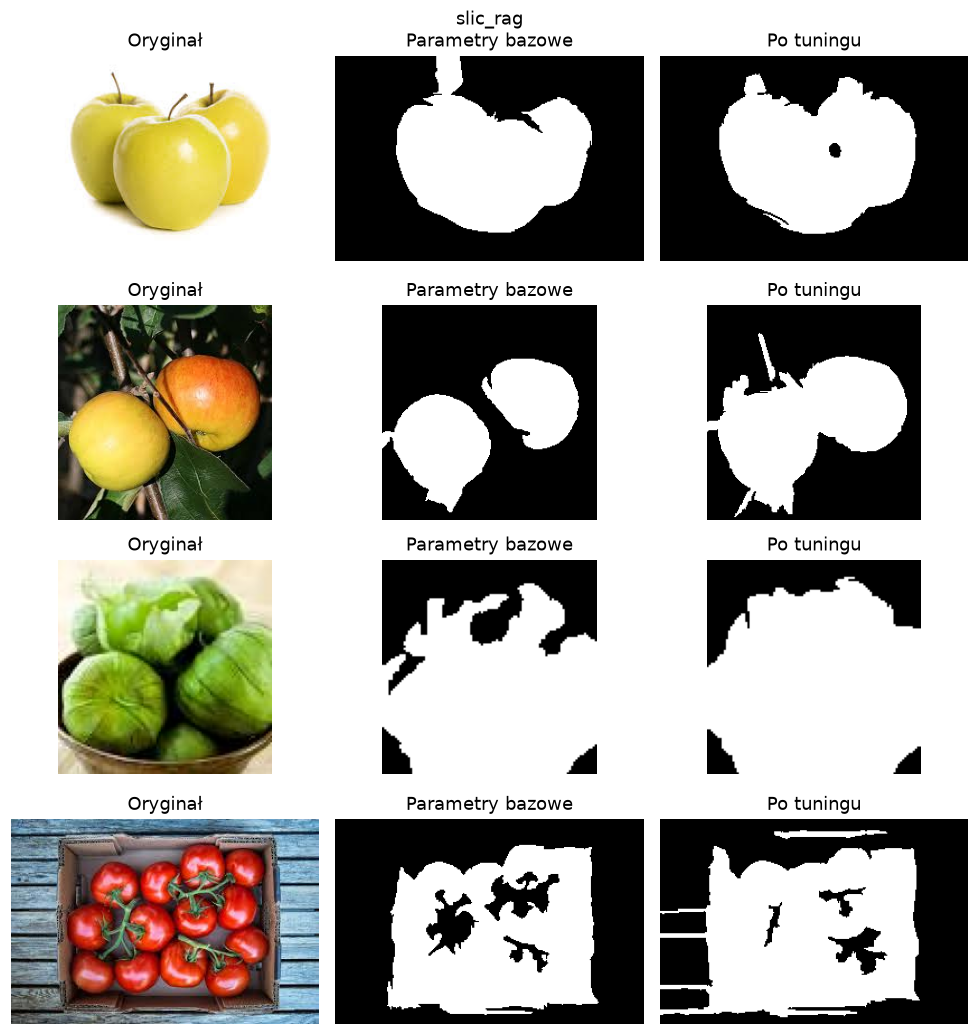

Wyeksportowane pary maska/obraz: 1173


In [22]:
export_rows=[]
for method,index in best_configs.items():
    params=configs[method][index]
    for row in manifest.itertuples():
        rgb=read_rgb(DATA/row.source);mask=tuned_mask(method,rgb,params)
        relative=Path(row.source+'.png');dest=TUNEROOT/method
        for folder in ('masks','images'): (dest/folder/relative).parent.mkdir(parents=True,exist_ok=True)
        Image.fromarray(mask.astype(np.uint8)*255).save(dest/'masks'/relative)
        Image.fromarray(np.dstack([rgb,mask.astype(np.uint8)*255])).save(dest/'images'/relative)
        with Image.open(dest/'masks'/relative) as saved: assert np.array_equal(np.array(saved)>0,mask)
        export_rows.append(dict(method=method,source=row.source,split=row.split,label=row.label,
            mask=str(Path(method)/'masks'/relative),image=str(Path(method)/'images'/relative),
            foreground_fraction=float(mask.mean())))
pd.DataFrame(export_rows).to_csv(TUNEROOT/'manifest.csv',index=False)
(TUNEROOT/'parameters.json').write_text(json.dumps({m:configs[m][i] for m,i in best_configs.items()},indent=2))
(TUNEROOT/'README.md').write_text('Parametry segmentacji wybrane przez walidację klasyfikacji tekstur wyłącznie na train.\n'
    'Podfoldery lab, hybrid, slic_rag: masks/ (PNG 0/255), images/ (PNG RGBA).\n'
    'Parametry: parameters.json. Mapowanie i diagnostyka: manifest.csv. Kod i ocena: sekcja 9 task3.ipynb.\n'
    'Nie jest to tuning IoU masek. Nie oceniano ponownie klasyfikacji na test.\n')
for method,oldroot in [('lab',SEG),('hybrid',HYBROOT),('slic_rag',SLICROOT)]:
    fig,axes=plt.subplots(len(fixed),3,figsize=(9,2.4*len(fixed)),squeeze=False)
    for axs,source in zip(axes,fixed):
        rgb=read_rgb(DATA/source)
        with Image.open(oldroot/'masks'/(source+'.png')) as im: before=np.array(im)>0
        with Image.open(TUNEROOT/method/'masks'/(source+'.png')) as im: after=np.array(im)>0
        for ax,img,title in zip(axs,[rgb,before,after],['Oryginał','Parametry bazowe','Po tuningu']):
            ax.imshow(img,cmap='gray' if img.ndim==2 else None);ax.set_title(title);ax.axis('off')
    fig.suptitle(method);plt.tight_layout();plt.savefig(TUNEOUT/f'{method}_before_after.png',bbox_inches='tight');plt.show()
print('Wyeksportowane pary maska/obraz:',len(export_rows))


## 9.3. Jak interpretować tuning
Wynik 5-fold dla zwycięzcy jest obciążony wyborem najlepszego wariantu. Zagnieżdżona walidacja lepiej ocenia całą procedurę, lecz przy trzech foldach ma dużą niepewność. Wzrost klasyfikacji może wynikać z zachowania charakterystycznego tła, a nie lepszej maski owocu. Dlatego trzeba oglądać porównania i docelowo ocenić IoU/Dice na ręcznie oznaczonym podzbiorze train.

Nie porównujemy liczb z tej sekcji wprost z wcześniejszym tuningiem SVM: tutaj klasyfikator jest celowo stały. Konfiguracja wybrana w całym train może różnić się od tych wybieranych w zewnętrznych foldach.

## 9.4. Wyniki tuningu
Sprawdzono **27 konfiguracji na 283 obrazach treningowych**. Poniższa tabela opisuje balanced accuracy klasyfikacji tekstur przy **stałym SVM**, nie dokładność masek.

| Metoda | 5-fold: baza → najlepsza konfiguracja | Zagnieżdżona walidacja: baza → tuning |
|---|---:|---:|
| Lab | 68,7% → **71,9%** | 68,3% → **69,7%** |
| Hybryda | 68,2% → **71,7%** | 68,3% → **68,0%** |
| SLIC/RAG | 72,0% → **72,6%** | 68,6% → **66,3%** |

Konfiguracje wybrane w całym train:
- **Lab:** pas tła 2% krótszego wymiaru, próg = 1,2 × Otsu, rozmiar morfologii ≈ 2% krótszego wymiaru.
- **Hybryda:** minimalne pole kandydata 1,5% obrazu, poparcie koloru ≥ 0,60, ocena kształtu ≥ 0,50.
- **SLIC/RAG:** 250 superpikseli, compactness=5, próg scalania Lab=25. Bazowa konfiguracja w bieżącej wersji notebooka ma 100 superpikseli.

**Ocena:** ograniczona siatka wskazuje niewielką, niepewną korzyść dla Lab. Dla hybrydy i SLIC/RAG wzrost wyniku służącego do wyboru konfiguracji nie przekłada się na zagnieżdżoną ocenę. Parametry wybierane w zewnętrznych foldach są różne, co wskazuje na niestabilność doboru. Nie ma podstaw, by automatycznie zastąpić wszystkie wersje bazowe konfiguracjami po tuningu.

Wizualnie hybryda odzyskuje niektóre pomijane obszary, ale może nadal zachować skrzynkę razem z owocami. Lab nadal nie radzi sobie z przykładem zielonych pomidorów, a SLIC/RAG po tuningu potrafi zachować więcej tła. Optymalizacja klasyfikacji nie jest równoważna poprawie granic owoców.

Wyeksportowano **1173 pary maska/obraz** (391 zdjęć × 3 metody) do `segmented_dataset_tuned/`. Konfiguracje są kandydatami wybranymi na całym train. Testowe zdjęcia tylko przetworzono — **nie obliczano nowego wyniku testowego klasyfikacji**.

Pełna siatka, wyniki foldów, kolejność obrazów w buforach cech, wybrane parametry i przykłady przed/po są w `outputs/segmentation_tuning/`. Każda maska została po zapisie ponownie odczytana i porównana z obliczoną. Kolejnym krokiem do tuningu jakości segmentacji jest przygotowanie ręcznych masek train i optymalizacja IoU/Dice.


# 10. Test konfiguracji wybranych na train
Oceniamy dokładnie parametry zapisane po tuningu, bez dalszego doboru na teście. Klasyfikator pozostaje taki jak w sekcji 9: 34 cechy LBP/GLCM, imputacja, standaryzacja, SVM RBF C=1, gamma=scale, class_weight=balanced. Uczy się na całym oczyszczonym train (283 obrazy).

Test to ten sam zbiór 84 obrazów po usunięciu duplikatów i sprzecznych etykiet. Dla porównania przeliczamy również bazowe maski przy **identycznym stałym klasyfikatorze**. Wcześniejsze sekcje dobierały także SVM i rodzaj cech, więc ich wyniki odpowiadają innemu eksperymentowi.

To wynik klasyfikacji po segmentacji, nie bezpośrednia ocena masek. Test był oglądany wcześniej; traktujemy ocenę jako eksploracyjną i nie zmieniamy na jej podstawie wybranych konfiguracji.

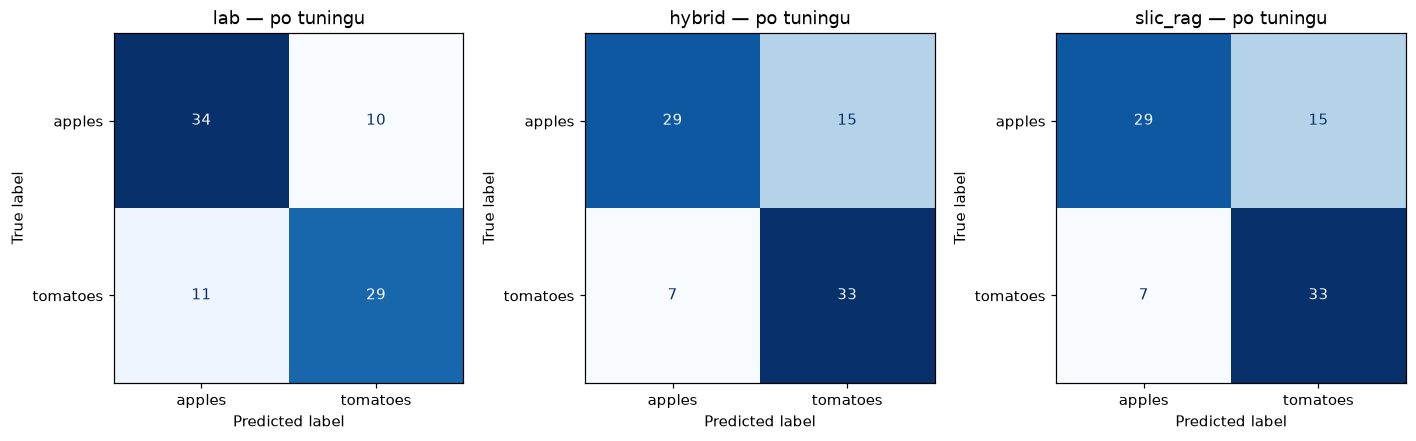

,method,variant,n_test,correct,accuracy,balanced_accuracy,f1_macro
0,lab,baseline,84,65,0.773810,0.776136,0.773777
1,lab,tuned,84,63,0.750000,0.748864,0.749111
2,hybrid,baseline,84,60,0.714286,0.717045,0.714124
3,hybrid,tuned,84,62,0.738095,0.742045,0.737500
4,slic_rag,baseline,84,65,0.773810,0.776136,0.773777
5,slic_rag,tuned,84,62,0.738095,0.742045,0.737500


Parametry segmentacji ustalone przed oceną testową:


,method,params
0,lab,"{""border_ratio"": 0.02, ""threshold_factor"": 1.2..."
1,hybrid,"{""min_area"": 0.015, ""color_support_threshold"":..."
2,slic_rag,"{""n_segments"": 250, ""compactness"": 5, ""merge_t..."


In [23]:
# Wczytanie zamrożonych konfiguracji, cech i kolejności train z sekcji 9.
TESTOUT=ROOT/'outputs'/'segmentation_tuning'/'test';TESTOUT.mkdir(parents=True,exist_ok=True)
TUNEDROOT=ROOT/'segmented_dataset_tuned'
PARAMOUT=ROOT/'outputs'/'segmentation_tuning'
chosen_table=pd.read_csv(PARAMOUT/'selected_parameters.csv')
chosen_params=json.loads((PARAMOUT/'selected_parameters.json').read_text())
assert chosen_params==json.loads((TUNEDROOT/'parameters.json').read_text())
order=pd.read_csv(PARAMOUT/'train_feature_order.csv')
original_features=pd.read_csv(ROOT/'outputs'/'texture_features.csv')
conflict_counts=original_features.groupby('pixel_hash').label.nunique()
conflict_set=set(conflict_counts[conflict_counts>1].index)
clean_features=original_features[~original_features.pixel_hash.isin(conflict_set)]
train_meta=clean_features[clean_features.split=='train'].drop_duplicates('pixel_hash')
test_meta=clean_features[clean_features.split=='test'].drop_duplicates('pixel_hash')
test_meta=test_meta[~test_meta.pixel_hash.isin(train_meta.pixel_hash)].reset_index(drop=True)
assert order.source.tolist()==train_meta.source.tolist()
assert order.pixel_hash.tolist()==train_meta.pixel_hash.tolist()
assert len(order)==283 and len(test_meta)==84
assert not set(order.pixel_hash)&set(test_meta.pixel_hash)
cols=[c for c in original_features if c.startswith(('lbp_','glcm_'))]
assert len(cols)==34

def frozen_classifier():
    return Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
        ('scale',StandardScaler()),('svm',SVC(C=1,gamma='scale',class_weight='balanced'))])

baseline_feature_paths={'lab':ROOT/'outputs'/'texture_features.csv',
    'hybrid':ROOT/'outputs'/'hybrid'/'texture_features.csv',
    'slic_rag':ROOT/'outputs'/'slic_rag'/'texture_features.csv'}
rows=[];prediction_rows=[];tuned_predictions={}
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,(method,baseline_path) in zip(axes,baseline_feature_paths.items()):
    candidate=int(chosen_table.set_index('method').loc[method,'candidate'])
    with np.load(PARAMOUT/f'{method}_train_features.npz') as cache:
        X_train=cache[f'candidate_{candidate}'].copy()
        X_baseline_train=cache['candidate_0'].copy()
    assert X_train.shape==(len(order),len(cols))
    X_test=[]
    for row in test_meta.itertuples():
        rgb=read_rgb(DATA/row.source)
        with Image.open(TUNEDROOT/method/'masks'/(row.source+'.png')) as im: mask=np.array(im)>0
        f,_=texture_features(rgb,mask)
        X_test.append([f[c] for c in cols])
    X_test=np.asarray(X_test,dtype=float)
    exported=test_meta[['source','label']].copy()
    exported[cols]=X_test;exported.to_csv(TESTOUT/f'{method}_test_features.csv',index=False)
    base=pd.read_csv(baseline_path).set_index('source')
    # Spójność bufora bazowych cech i tabel eksportowanych wcześniej.
    assert np.allclose(X_baseline_train,base.loc[order.source,cols].to_numpy(),equal_nan=True)
    for variant,fit_X,predict_X in [('baseline',X_baseline_train,base.loc[test_meta.source,cols]),
                                   ('tuned',X_train,X_test)]:
        model=frozen_classifier().fit(fit_X,order.label)
        pred=model.predict(np.asarray(predict_X))
        rows.append(dict(method=method,variant=variant,n_test=len(pred),
            correct=int((pred==test_meta.label).sum()),accuracy=accuracy_score(test_meta.label,pred),
            balanced_accuracy=balanced_accuracy_score(test_meta.label,pred),
            f1_macro=f1_score(test_meta.label,pred,average='macro')))
        for source,label,prediction in zip(test_meta.source,test_meta.label,pred):
            prediction_rows.append(dict(method=method,variant=variant,source=source,label=label,prediction=prediction))
        if variant=='tuned':
            tuned_predictions[method]=pred
            ConfusionMatrixDisplay.from_predictions(test_meta.label,pred,ax=ax,cmap='Blues',colorbar=False)
            ax.set_title(method+' — po tuningu')
            report=classification_report(test_meta.label,pred,output_dict=True,zero_division=0)
            pd.DataFrame(report).T.to_csv(TESTOUT/f'{method}_classification_report.csv')
plt.tight_layout();plt.savefig(TESTOUT/'tuned_test_confusion_matrices.png',bbox_inches='tight');plt.show()
tuning_test_results=pd.DataFrame(rows)
display(tuning_test_results)
tuning_test_results.to_csv(TESTOUT/'test_metrics.csv',index=False)
pd.DataFrame(prediction_rows).to_csv(TESTOUT/'test_predictions.csv',index=False)
print('Parametry segmentacji ustalone przed oceną testową:')
display(chosen_table[['method','params']])


## 10.1. Wyniki testowe zamrożonych konfiguracji
Ocena na **84 tych samych obrazach**, trening na 283 obrazach. Wyniki dotyczą stałego SVM C=1, gamma=scale i połączonych cech LBP/GLCM.

| Segmentacja | Accuracy bazowa | Accuracy po tuningu | Balanced accuracy po tuningu | Macro F1 po tuningu |
|---|---:|---:|---:|---:|
| Lab | 77,4% (65/84) | **75,0% (63/84)** | 74,9% | 74,9% |
| Hybryda | 71,4% (60/84) | **73,8% (62/84)** | 74,2% | 73,8% |
| SLIC/RAG | 77,4% (65/84) | **73,8% (62/84)** | 74,2% | 73,8% |

Tuning poprawił accuracy hybrydy o 2 odpowiedzi, a pogorszył Lab o 2 i SLIC/RAG o 3. Na małym teście różnice są niewielkie i nie dowodzą trwałej przewagi. Wybrano konfiguracje według walidacji train, nie według tabeli testowej; parametrów po tej ocenie nie zmieniono.

Wyniki bazowe tej tabeli różnią się od wcześniejszych sekcji, gdzie osobno dobierano parametry SVM i rodzaj cech. Tutaj izolujemy wpływ tuningu segmentacji, zachowując ten sam klasyfikator. Najwyższe accuracy wśród **dobranych konfiguracji** ma Lab (75,0%), ale przewaga nad pozostałymi to tylko jedna odpowiedź.

Zapisano metryki, raporty klas, predykcje i macierze pomyłek w `outputs/segmentation_tuning/test/`. To ocena klasyfikacji po segmentacji, a nie IoU masek.
